# Plant Disease Detection - PyTorch GPU Version

**Converted from TensorFlow/Keras to PyTorch with CUDA GPU acceleration**

Key changes:
- All models run on GPU (CUDA) if available, CPU otherwise
- AdaPlant custom optimizer rewritten as `torch.optim.Optimizer`
- `tf.data.Dataset` replaced with `torch.utils.data.DataLoader`
- `torchvision.models` for MobileNetV2 and ResNet50
- Custom training loop with proper GPU tensor management
- Visualization code unchanged (matplotlib/seaborn)

In [1]:
import os
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T
import torchvision.models as models
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import pandas as pd
from collections import defaultdict
import warnings
import time
import json
warnings.filterwarnings('ignore')

# ============================================================
# GPU / DEVICE SETUP
# ============================================================
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"PyTorch Version: {torch.__version__}")
print(f"CUDA Available:  {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU Device:     {torch.cuda.get_device_name(0)}")
    # print(f"GPU Memory:"      {torch.cuda.get_device_properties(0).total_mem / 1e9:.1f} GB")
print(f"Using Device:    {device}")
print("=" * 70)

# ============================================================
# SET SEEDS FOR REPRODUCIBILITY
# ============================================================
np.random.seed(42)
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed(42)
    torch.cuda.manual_seed_all(42)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

# ============================================================
# CONFIGURATION
# ============================================================
CONFIG = {
    'data_dir': 'New Plant Diseases Dataset(Augmented)/train',
    'img_size': (32, 32),
    'batch_size': 10,
    'epochs': 200,
    'images_per_class': 200,
    'num_classes': 38,
    'learning_rate': 0.001,
    'val_split': 0.2,
    'test_split': 0.1,
    'num_workers': 4 if torch.cuda.is_available() else 0,
}

print("Configuration:")
for k, v in CONFIG.items():
    print(f"  {k}: {v}")
print("=" * 70)

PyTorch Version: 2.14.0+cpu
CUDA Available:  False
Using Device:    cpu
Configuration:
  data_dir: New Plant Diseases Dataset(Augmented)/train
  img_size: (32, 32)
  batch_size: 10
  epochs: 200
  images_per_class: 200
  num_classes: 38
  learning_rate: 0.001
  val_split: 0.2
  test_split: 0.1
  num_workers: 0


In [2]:
# ============================================================
# NOVEL OPTIMIZER: AdaPlant Optimizer (PyTorch)
# ============================================================
"""
AdaPlant Optimizer - Novel Optimizer for Plant Disease Detection

Key Innovations:
1. Adaptive Learning Rate with Gradient Variance Awareness
2. Momentum with Gradient Diversity Weighting
3. Layer-wise Gradient Normalization
4. Disease-aware Gradient Clipping
5. Cyclical Second Moment with Memory Decay

Formula:
- m_t = beta_1 * m_{t-1} + (1 - beta_1) * g_t          [First Moment]
- v_t = beta_2 * v_{t-1} + (1 - beta_2) * g_t^2         [Second Moment]
- d_t = beta_3 * d_{t-1} + (1 - beta_3) * |g_t - g_{t-1}| [diversity]
- m_hat_t  = m_t / (1 - beta_1^t)                        [bias correct]
- v_hat_t  = v_t / (1 - beta_2^t)                        [bias correct]
- delta_t   = 1 + gamma * d_t                             [diversity factor]
- eta_eff = eta * (1 + alpha * cos(pi * t / T))            [cyclical lr]
- eps_eff = eps * (1 + mean(|g_t|))                   [adaptive eps]
- theta_t   = theta_{t-1} - eta_eff * (m_hat_t/(sqrt(v_hat_t) + eps_eff)) * delta_t - lambda*theta
"""

class AdaPlantOptimizer(optim.Optimizer):
    """
    AdaPlant: Adaptive Plant Disease Detection Optimizer (PyTorch)

    Novel Components:
    1. Cyclical Learning Rate - escapes local minima
    2. Gradient Diversity Weighting - tracks gradient direction changes
    3. Adaptive Epsilon Scaling - scales with gradient magnitude
    4. Decoupled Weight Decay - prevents over-regularization
    5. Variance-aware Momentum - combines Adam + extra diversity term
    """

    def __init__(
        self,
        params,
        learning_rate=0.01,
        beta_1=0.9,
        beta_2=0.999,
        beta_3=0.9,
        epsilon=1e-7,
        gamma=0.1,
        alpha=0.3,
        cycle_period=10,
        weight_decay=1e-4,
        clipnorm=1.0,
    ):
        defaults = dict(
            lr=learning_rate,
            beta_1=beta_1,
            beta_2=beta_2,
            beta_3=beta_3,
            epsilon=epsilon,
            gamma=gamma,
            alpha=alpha,
            cycle_period=cycle_period,
            weight_decay=weight_decay,
            clipnorm=clipnorm,
        )
        super(AdaPlantOptimizer, self).__init__(params, defaults)

    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad():
                loss = closure()

        for group in self.param_groups:
            lr      = group['lr']
            beta_1  = group['beta_1']
            beta_2  = group['beta_2']
            beta_3  = group['beta_3']
            epsilon = group['epsilon']
            gamma   = group['gamma']
            alpha   = group['alpha']
            cycle_period = group['cycle_period']
            weight_decay = group['weight_decay']
            clipnorm = group['clipnorm']

            for p in group['params']:
                if p.grad is None:
                    continue

                grad = p.grad.data

                # Initialize state on first call
                state = self.state[p]
                if len(state) == 0:
                    state['step'] = 0
                    state['m'] = torch.zeros_like(p.data)
                    state['v'] = torch.zeros_like(p.data)
                    state['d'] = torch.zeros_like(p.data)
                    state['g_prev'] = torch.zeros_like(p.data)

                m, v, d, g_prev = state['m'], state['v'], state['d'], state['g_prev']
                state['step'] += 1
                t = state['step']

                # Step 1: Gradient Clipping
                grad_norm = grad.norm()
                if grad_norm > clipnorm:
                    grad = grad * (clipnorm / (grad_norm + 1e-12))

                # Step 2: First Moment (Momentum)
                m.mul_(beta_1).add_(grad, alpha=1.0 - beta_1)

                # Step 3: Second Moment (Variance)
                v.mul_(beta_2).addcmul_(grad, grad, value=1.0 - beta_2)

                # Step 4: Bias Correction
                m_hat = m / (1.0 - beta_1 ** t)
                v_hat = v / (1.0 - beta_2 ** t)

                # Step 5: Gradient Diversity (Novel)
                grad_diff = torch.abs(grad - g_prev)
                d.mul_(beta_3).add_(grad_diff, alpha=1.0 - beta_3)
                g_prev.copy_(grad)

                diversity_factor = 1.0 + gamma * d

                # Step 6: Cyclical Learning Rate (Novel)
                cycle_pos = t % cycle_period
                cycle_factor = 1.0 + alpha * np.cos(np.pi * cycle_pos / cycle_period)
                effective_lr = lr * cycle_factor

                # Step 7: Adaptive Epsilon (Novel)
                adaptive_eps = epsilon * (1.0 + grad.abs().mean())

                # Step 8: Compute Parameter Update
                update = effective_lr * (m_hat / (v_hat.sqrt() + adaptive_eps))
                update = update * diversity_factor

                # Step 9: Decoupled Weight Decay
                weight_decay_term = weight_decay * p.data

                # Step 10: Apply Update
                p.data.add_(-(update + weight_decay_term))

        return loss


print("AdaPlant Optimizer (PyTorch) defined successfully!")
print(f"  Will run on: {device}")

AdaPlant Optimizer (PyTorch) defined successfully!
  Will run on: cpu


In [3]:
# ============================================================
# DATA LOADING: PyTorch Dataset + DataLoader
# ============================================================

class PlantDiseaseDataset(Dataset):
    """Custom PyTorch Dataset that loads images from disk"""

    def __init__(self, image_paths, labels, img_size, num_classes, transform=None):
        self.image_paths = image_paths
        self.labels = labels
        self.img_size = img_size
        self.num_classes = num_classes
        self.transform = transform

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img_path = self.image_paths[idx]
        label = self.labels[idx]

        # Load image with PIL
        image = Image.open(img_path).convert('RGB')
        image = image.resize(self.img_size, Image.BILINEAR)

        if self.transform:
            image = self.transform(image)

        return image, label


class PlantDiseaseDataLoader:
    """Custom data loader that reads exactly N images per class"""

    def __init__(self, data_dir, images_per_class=100, img_size=(224, 224)):
        self.data_dir = data_dir
        self.images_per_class = images_per_class
        self.img_size = img_size
        self.class_names = sorted(os.listdir(data_dir))
        self.num_classes = len(self.class_names)
        self.class_to_idx = {cls: idx for idx, cls in enumerate(self.class_names)}

        print(f"\n{'='*60}")
        print(f"Dataset Information:")
        print(f"{'='*60}")
        print(f"Data Directory: {data_dir}")
        print(f"Number of Classes: {self.num_classes}")
        print(f"Images per Class: {images_per_class}")
        print(f"Total Images: {self.num_classes * images_per_class}")
        print(f"Image Size: {img_size}")
        print(f"{'='*60}")

    def load_dataset(self, val_split=0.2, test_split=0.1):
        """Load dataset with exactly N images per class"""
        all_images = []
        all_labels = []
        class_counts = {}

        print("\nLoading images from each class:")
        print("-" * 50)

        for class_name in self.class_names:
            class_dir = os.path.join(self.data_dir, class_name)

            if not os.path.isdir(class_dir):
                continue

            img_extensions = ['.jpg', '.jpeg', '.png', '.JPG', '.JPEG', '.PNG']
            img_files = [
                f for f in os.listdir(class_dir)
                if any(f.endswith(ext) for ext in img_extensions)
            ]

            np.random.shuffle(img_files)
            selected_files = img_files[:self.images_per_class]

            class_idx = self.class_to_idx[class_name]
            class_counts[class_name] = len(selected_files)

            for img_file in selected_files:
                img_path = os.path.join(class_dir, img_file)
                all_images.append(img_path)
                all_labels.append(class_idx)

            print(f"  {class_name[:50]:<50} | {len(selected_files):>3} images")

        print(f"\nTotal images loaded: {len(all_images)}")

        # Shuffle dataset
        combined = list(zip(all_images, all_labels))
        np.random.shuffle(combined)
        all_images, all_labels = zip(*combined)
        all_images = list(all_images)
        all_labels = list(all_labels)

        # Split dataset
        n = len(all_images)
        n_test = int(n * test_split)
        n_val = int(n * val_split)
        n_train = n - n_test - n_val

        train_images = all_images[:n_train]
        train_labels = all_labels[:n_train]
        val_images = all_images[n_train:n_train + n_val]
        val_labels = all_labels[n_train:n_train + n_val]
        test_images = all_images[n_train + n_val:]
        test_labels = all_labels[n_train + n_val:]

        print(f"\nDataset Split:")
        print(f"  Train: {len(train_images)} images")
        print(f"  Val:   {len(val_images)} images")
        print(f"  Test:  {len(test_images)} images")

        return (
            (train_images, train_labels),
            (val_images, val_labels),
            (test_images, test_labels),
            class_counts
        )

    def create_dataloaders(self, splits, batch_size=32, num_workers=0):
        """Create PyTorch DataLoaders from image paths and labels"""
        (train_paths, train_labels), (val_paths, val_labels), (test_paths, test_labels) = splits

        # Train transform with augmentation
        train_transform = T.Compose([
            T.Resize(self.img_size),
            T.RandomHorizontalFlip(),
            T.RandomVerticalFlip(),
            T.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.1),
            T.ToTensor(),
            T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])

        # Val/Test transform (no augmentation)
        eval_transform = T.Compose([
            T.Resize(self.img_size),
            T.ToTensor(),
            T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])

        train_dataset = PlantDiseaseDataset(
            train_paths, train_labels, self.img_size, self.num_classes, train_transform
        )
        val_dataset = PlantDiseaseDataset(
            val_paths, val_labels, self.img_size, self.num_classes, eval_transform
        )
        test_dataset = PlantDiseaseDataset(
            test_paths, test_labels, self.img_size, self.num_classes, eval_transform
        )

        train_loader = DataLoader(
            train_dataset, batch_size=batch_size, shuffle=True,
            num_workers=num_workers, pin_memory=True if torch.cuda.is_available() else False
        )
        val_loader = DataLoader(
            val_dataset, batch_size=batch_size, shuffle=False,
            num_workers=num_workers, pin_memory=True if torch.cuda.is_available() else False
        )
        test_loader = DataLoader(
            test_dataset, batch_size=batch_size, shuffle=False,
            num_workers=num_workers, pin_memory=True if torch.cuda.is_available() else False
        )

        return train_loader, val_loader, test_loader


# ============================================================
# Load the Dataset
# ============================================================
data_loader = PlantDiseaseDataLoader(
    data_dir=CONFIG['data_dir'],
    images_per_class=CONFIG['images_per_class'],
    img_size=CONFIG['img_size']
)

(train_data, val_data, test_data, class_counts) = data_loader.load_dataset(
    val_split=CONFIG['val_split'],
    test_split=CONFIG['test_split']
)

train_loader, val_loader, test_loader = data_loader.create_dataloaders(
    (train_data, val_data, test_data),
    batch_size=CONFIG['batch_size'],
    num_workers=CONFIG['num_workers']
)

print(f"\nDatasets created successfully!")
print(f"  Train batches: {len(train_loader)}")
print(f"  Val batches:   {len(val_loader)}")
print(f"  Test batches:  {len(test_loader)}")
print(f"  Device: {device}")


Dataset Information:
Data Directory: New Plant Diseases Dataset(Augmented)/train
Number of Classes: 38
Images per Class: 200
Total Images: 7600
Image Size: (32, 32)

Loading images from each class:
--------------------------------------------------
  Apple___Apple_scab                                 | 200 images
  Apple___Black_rot                                  | 200 images
  Apple___Cedar_apple_rust                           | 200 images
  Apple___healthy                                    | 200 images
  Blueberry___healthy                                | 200 images
  Cherry_(including_sour)___Powdery_mildew           | 200 images
  Cherry_(including_sour)___healthy                  | 200 images
  Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot | 200 images
  Corn_(maize)___Common_rust_                        | 200 images
  Corn_(maize)___Northern_Leaf_Blight                | 200 images
  Corn_(maize)___healthy                             | 200 images
  Grape___Black_rot     

In [4]:
# ============================================================
# MODEL BUILDER (PyTorch / torchvision)
# ============================================================

class PlantDiseaseModelBuilder:
    """Builds MobileNetV2 and ResNet50 models with frozen base layers"""

    def __init__(self, num_classes, img_size=(32, 32)):
        self.num_classes = num_classes
        self.img_size = img_size

    def build_mobilenetv2(self, freeze_base=True):
        """
        Build MobileNetV2 with frozen base layers.
        Only the classification head is trainable.
        """
        # Load pre-trained base
        base_model = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.IMAGENET1K_V1)

        # Freeze base model
        if freeze_base:
            for param in base_model.features.parameters():
                param.requires_grad = False
            print(f"\nMobileNetV2 base: FROZEN")

        # Replace classifier
        num_ftrs = base_model.classifier[1].in_features
        base_model.classifier = nn.Sequential(
            nn.Dropout(p=0.4),
            nn.Linear(num_ftrs, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(inplace=True),
            nn.Dropout(p=0.3),
            nn.Linear(512, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(p=0.3),
            nn.Linear(256, self.num_classes),
        )

        model = base_model.to(device)

        # Count parameters
        total = sum(p.numel() for p in model.parameters())
        trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
        print(f"  Total params: {total:,}")
        print(f"  Trainable params: {trainable:,}")
        print(f"  Frozen params: {total - trainable:,}")

        return model

    def build_resnet50(self, freeze_base=True):
        """
        Build ResNet50 with frozen base layers.
        Only the classification head is trainable.
        """
        # Load pre-trained base
        base_model = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V1)

        # Freeze base model
        if freeze_base:
            for param in base_model.parameters():
                param.requires_grad = False
            print(f"\nResNet50 base: FROZEN")

        # Replace classifier head
        num_ftrs = base_model.fc.in_features
        base_model.fc = nn.Sequential(
            nn.Dropout(p=0.4),
            nn.Linear(num_ftrs, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(inplace=True),
            nn.Dropout(p=0.3),
            nn.Linear(512, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(p=0.3),
            nn.Linear(256, self.num_classes),
        )

        model = base_model.to(device)

        # Count parameters
        total = sum(p.numel() for p in model.parameters())
        trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
        print(f"  Total params: {total:,}")
        print(f"  Trainable params: {trainable:,}")
        print(f"  Frozen params: {total - trainable:,}")

        return model


model_builder = PlantDiseaseModelBuilder(
    num_classes=CONFIG['num_classes'],
    img_size=CONFIG['img_size']
)

print("Model builder initialized!")

Model builder initialized!


In [5]:
# ============================================================
# OPTIMIZER DEFINITIONS
# ============================================================

def get_optimizers(model, learning_rate=0.001):
    """Define all optimizers to compare (only trainable params)"""
    trainable_params = [p for p in model.parameters() if p.requires_grad]

    optimizers = {
        # --- Novel Optimizer ---
        'AdaPlant': AdaPlantOptimizer(
            trainable_params,
            learning_rate=learning_rate,
            beta_1=0.9,
            beta_2=0.999,
            beta_3=0.9,
            epsilon=1e-7,
            gamma=0.1,
            alpha=0.3,
            cycle_period=10,
            weight_decay=1e-4,
            clipnorm=1.0
        ),

        # --- Baseline Optimizers ---
        'SGD': optim.SGD(
            trainable_params,
            lr=learning_rate,
            momentum=0.9,
            nesterov=True
        ),

        'Adam': optim.Adam(
            trainable_params,
            lr=learning_rate,
            betas=(0.9, 0.999),
            eps=1e-7
        ),

        'RMSprop': optim.RMSprop(
            trainable_params,
            lr=learning_rate,
            alpha=0.9,
            eps=1e-7
        ),

        'Adadelta': optim.Adadelta(
            trainable_params,
            lr=1.0,
            rho=0.95,
            eps=1e-7
        ),
    }

    return optimizers


print("\nOptimizers to compare:")
print("=" * 50)
optimizer_names = ['AdaPlant', 'SGD', 'Adam', 'RMSprop', 'Adadelta']
for name in optimizer_names:
    marker = " <-- NOVEL" if name == 'AdaPlant' else ""
    print(f"  {name:<15}{marker}")
print("=" * 50)


Optimizers to compare:
  AdaPlant        <-- NOVEL
  SGD            
  Adam           
  RMSprop        
  Adadelta       


In [ ]:
# ============================================================
# TRAINING ENGINE
# ============================================================

class ExperimentTracker:
    """Tracks and stores all experiment results"""

    def __init__(self):
        self.results = {}
        self.histories = {}
        self.training_times = {}
        self.test_metrics = {}

    def add_result(self, model_name, optimizer_name, history,
                   training_time, test_metrics):
        key = f"{model_name}_{optimizer_name}"
        self.results[key] = {
            'model': model_name,
            'optimizer': optimizer_name,
            'history': history,
            'training_time': training_time,
            'test_metrics': test_metrics
        }
        self.histories[key] = history
        self.training_times[key] = training_time
        self.test_metrics[key] = test_metrics

    def get_summary_df(self):
        """Create summary DataFrame"""
        rows = []
        for key, result in self.results.items():
            row = {
                'Model': result['model'],
                'Optimizer': result['optimizer'],
                'Best_Val_Acc': max(result['history']['val_accuracy']),
                'Final_Train_Acc': result['history']['accuracy'][-1],
                'Final_Val_Acc': result['history']['val_accuracy'][-1],
                'Best_Val_Loss': min(result['history']['val_loss']),
                'Final_Train_Loss': result['history']['loss'][-1],
                'Final_Val_Loss': result['history']['val_loss'][-1],
                'Test_Accuracy': result['test_metrics']['accuracy'],
                'Test_Loss': result['test_metrics']['loss'],
                'Training_Time_min': result['training_time'] / 60,
            }
            rows.append(row)
        return pd.DataFrame(rows)


def train_one_epoch(model, loader, criterion, optimizer, device):
    """Train for one epoch, return loss and accuracy"""
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()

    epoch_loss = running_loss / total
    epoch_acc = correct / total
    return epoch_loss, epoch_acc


def validate(model, loader, criterion, device):
    """Validate, return loss and accuracy"""
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)
            _, predicted = outputs.max(1)
            total += labels.size(0)
            correct += predicted.eq(labels).sum().item()

    epoch_loss = running_loss / total
    epoch_acc = correct / total
    return epoch_loss, epoch_acc


def train_model(model_name, optimizer_name, optimizer_class,
                train_loader, val_loader, test_loader, epochs, tracker):
    """Train a single model-optimizer combination"""

    print(f"\n{'='*65}")
    print(f"  Training: {model_name} + {optimizer_name}")
    print(f"{'='*65}")

    # Build fresh model
    if model_name == 'MobileNetV2':
        model = model_builder.build_mobilenetv2(freeze_base=True)
    else:
        model = model_builder.build_resnet50(freeze_base=True)

    # Create optimizer
    if optimizer_name == 'AdaPlant':
        trainable_params = [p for p in model.parameters() if p.requires_grad]
        optimizer = AdaPlantOptimizer(
            trainable_params,
            learning_rate=CONFIG['learning_rate'],
            beta_1=0.9, beta_2=0.999, beta_3=0.9,
            epsilon=1e-7, gamma=0.1, alpha=0.3,
            cycle_period=10, weight_decay=1e-4, clipnorm=1.0
        )
    elif optimizer_name == 'SGD':
        trainable_params = [p for p in model.parameters() if p.requires_grad]
        optimizer = optim.SGD(trainable_params, lr=CONFIG['learning_rate'], momentum=0.9, nesterov=True)
    elif optimizer_name == 'Adam':
        trainable_params = [p for p in model.parameters() if p.requires_grad]
        optimizer = optim.Adam(trainable_params, lr=CONFIG['learning_rate'], betas=(0.9, 0.999), eps=1e-7)
    elif optimizer_name == 'RMSprop':
        trainable_params = [p for p in model.parameters() if p.requires_grad]
        optimizer = optim.RMSprop(trainable_params, lr=CONFIG['learning_rate'], alpha=0.9, eps=1e-7)
    elif optimizer_name == 'Adadelta':
        trainable_params = [p for p in model.parameters() if p.requires_grad]
        optimizer = optim.Adadelta(trainable_params, lr=1.0, rho=0.95, eps=1e-7)

    # Loss function (CrossEntropyLoss includes softmax)
    criterion = nn.CrossEntropyLoss().to(device)

    # Learning rate scheduler (ReduceLROnPlateau)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode='max', factor=0.5, patience=3, min_lr=1e-7
    )

    # History tracking
    history = {'loss': [], 'accuracy': [], 'val_loss': [], 'val_accuracy': []}
    best_val_acc = 0.0
    patience_counter = 0
    best_state = None

    # Train
    start_time = time.time()

    for epoch in range(1, epochs + 1):
        train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
        val_loss, val_acc = validate(model, val_loader, criterion, device)

        history['loss'].append(train_loss)
        history['accuracy'].append(train_acc)
        history['val_loss'].append(val_loss)
        history['val_accuracy'].append(val_acc)

        # Scheduler step
        scheduler.step(val_acc)

        # Early stopping
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            patience_counter = 0
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
        else:
            patience_counter += 1
            if patience_counter >= 5:
                print(f"  Early stopping at epoch {epoch}")
                break

        current_lr = optimizer.param_groups[0]['lr']
        print(
            f"Epoch {epoch}/{epochs} - "
            f"loss: {train_loss:.4f} - accuracy: {train_acc:.4f} - "
            f"val_loss: {val_loss:.4f} - val_accuracy: {val_acc:.4f} - "
            f"lr: {current_lr:.4e}"
        )

    training_time = time.time() - start_time

    # Restore best weights
    if best_state is not None:
        model.load_state_dict(best_state)
        model = model.to(device)

    # Evaluate on test set
    print(f"\nEvaluating on test set...")
    test_loss, test_acc = validate(model, test_loader, criterion, device)
    test_metrics = {'loss': test_loss, 'accuracy': test_acc}

    print(f"\n  Results: {model_name} + {optimizer_name}")
    print(f"  |  Test Accuracy:  {test_acc:.4f} ({test_acc*100:.2f}%)")
    print(f"  |  Test Loss:      {test_loss:.4f}")
    print(f"  |  Best Val Acc:   {best_val_acc:.4f}")
    print(f"  |  Training Time:  {training_time/60:.2f} min")

    # Save results
    tracker.add_result(
        model_name, optimizer_name,
        history, training_time, test_metrics
    )

    # Free GPU memory
    del model
    del optimizer
    del scheduler
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return history


# ============================================================
# RUN ALL EXPERIMENTS
# ============================================================
tracker = ExperimentTracker()

models_to_test = ['MobileNetV2', 'ResNet50']
optimizer_names = ['AdaPlant', 'SGD', 'Adam', 'RMSprop', 'Adadelta']

print("\n" + "=" * 65)
print("  STARTING ALL EXPERIMENTS")
print(f"  Models: {models_to_test}")
print(f"  Optimizers: {optimizer_names}")
print(f"  Epochs: {CONFIG['epochs']}")
print(f"  Device: {device}")
print("=" * 65)

for model_name in models_to_test:
    for opt_name in optimizer_names:
        history = train_model(
            model_name=model_name,
            optimizer_name=opt_name,
            optimizer_class=opt_name,
            train_loader=train_loader,
            val_loader=val_loader,
            test_loader=test_loader,
            epochs=CONFIG['epochs'],
            tracker=tracker
        )

print("\n" + "=" * 65)
print("  ALL EXPERIMENTS COMPLETED!")
print("=" * 65)


  STARTING ALL EXPERIMENTS
  Models: ['MobileNetV2', 'ResNet50']
  Optimizers: ['AdaPlant', 'SGD', 'Adam', 'RMSprop', 'Adadelta']
  Epochs: 200
  Device: cpu

  Training: MobileNetV2 + AdaPlant
Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to C:\Users\MANO/.cache\torch\hub\checkpoints\mobilenet_v2-b0353104.pth


100%|██████████| 13.6M/13.6M [00:02<00:00, 6.91MB/s]



MobileNetV2 base: FROZEN
  Total params: 3,021,862
  Trainable params: 797,990
  Frozen params: 2,223,872
Epoch 1/200 - loss: 3.1614 - accuracy: 0.1556 - val_loss: 2.5912 - val_accuracy: 0.3020 - lr: 1.0000e-03
Epoch 2/200 - loss: 2.8155 - accuracy: 0.2308 - val_loss: 2.4260 - val_accuracy: 0.3572 - lr: 1.0000e-03
Epoch 3/200 - loss: 2.7020 - accuracy: 0.2549 - val_loss: 2.2941 - val_accuracy: 0.3724 - lr: 1.0000e-03
Epoch 4/200 - loss: 2.6887 - accuracy: 0.2602 - val_loss: 2.1938 - val_accuracy: 0.4132 - lr: 1.0000e-03
Epoch 5/200 - loss: 2.6430 - accuracy: 0.2701 - val_loss: 2.2801 - val_accuracy: 0.4059 - lr: 1.0000e-03
Epoch 6/200 - loss: 2.5982 - accuracy: 0.2761 - val_loss: 2.1919 - val_accuracy: 0.4026 - lr: 1.0000e-03
Epoch 7/200 - loss: 2.6036 - accuracy: 0.2812 - val_loss: 2.1816 - val_accuracy: 0.4204 - lr: 1.0000e-03
Epoch 8/200 - loss: 2.5620 - accuracy: 0.2921 - val_loss: 2.1372 - val_accuracy: 0.4000 - lr: 1.0000e-03
Epoch 9/200 - loss: 2.5153 - accuracy: 0.2996 - val_l


  GENERATING ALL VISUALIZATIONS


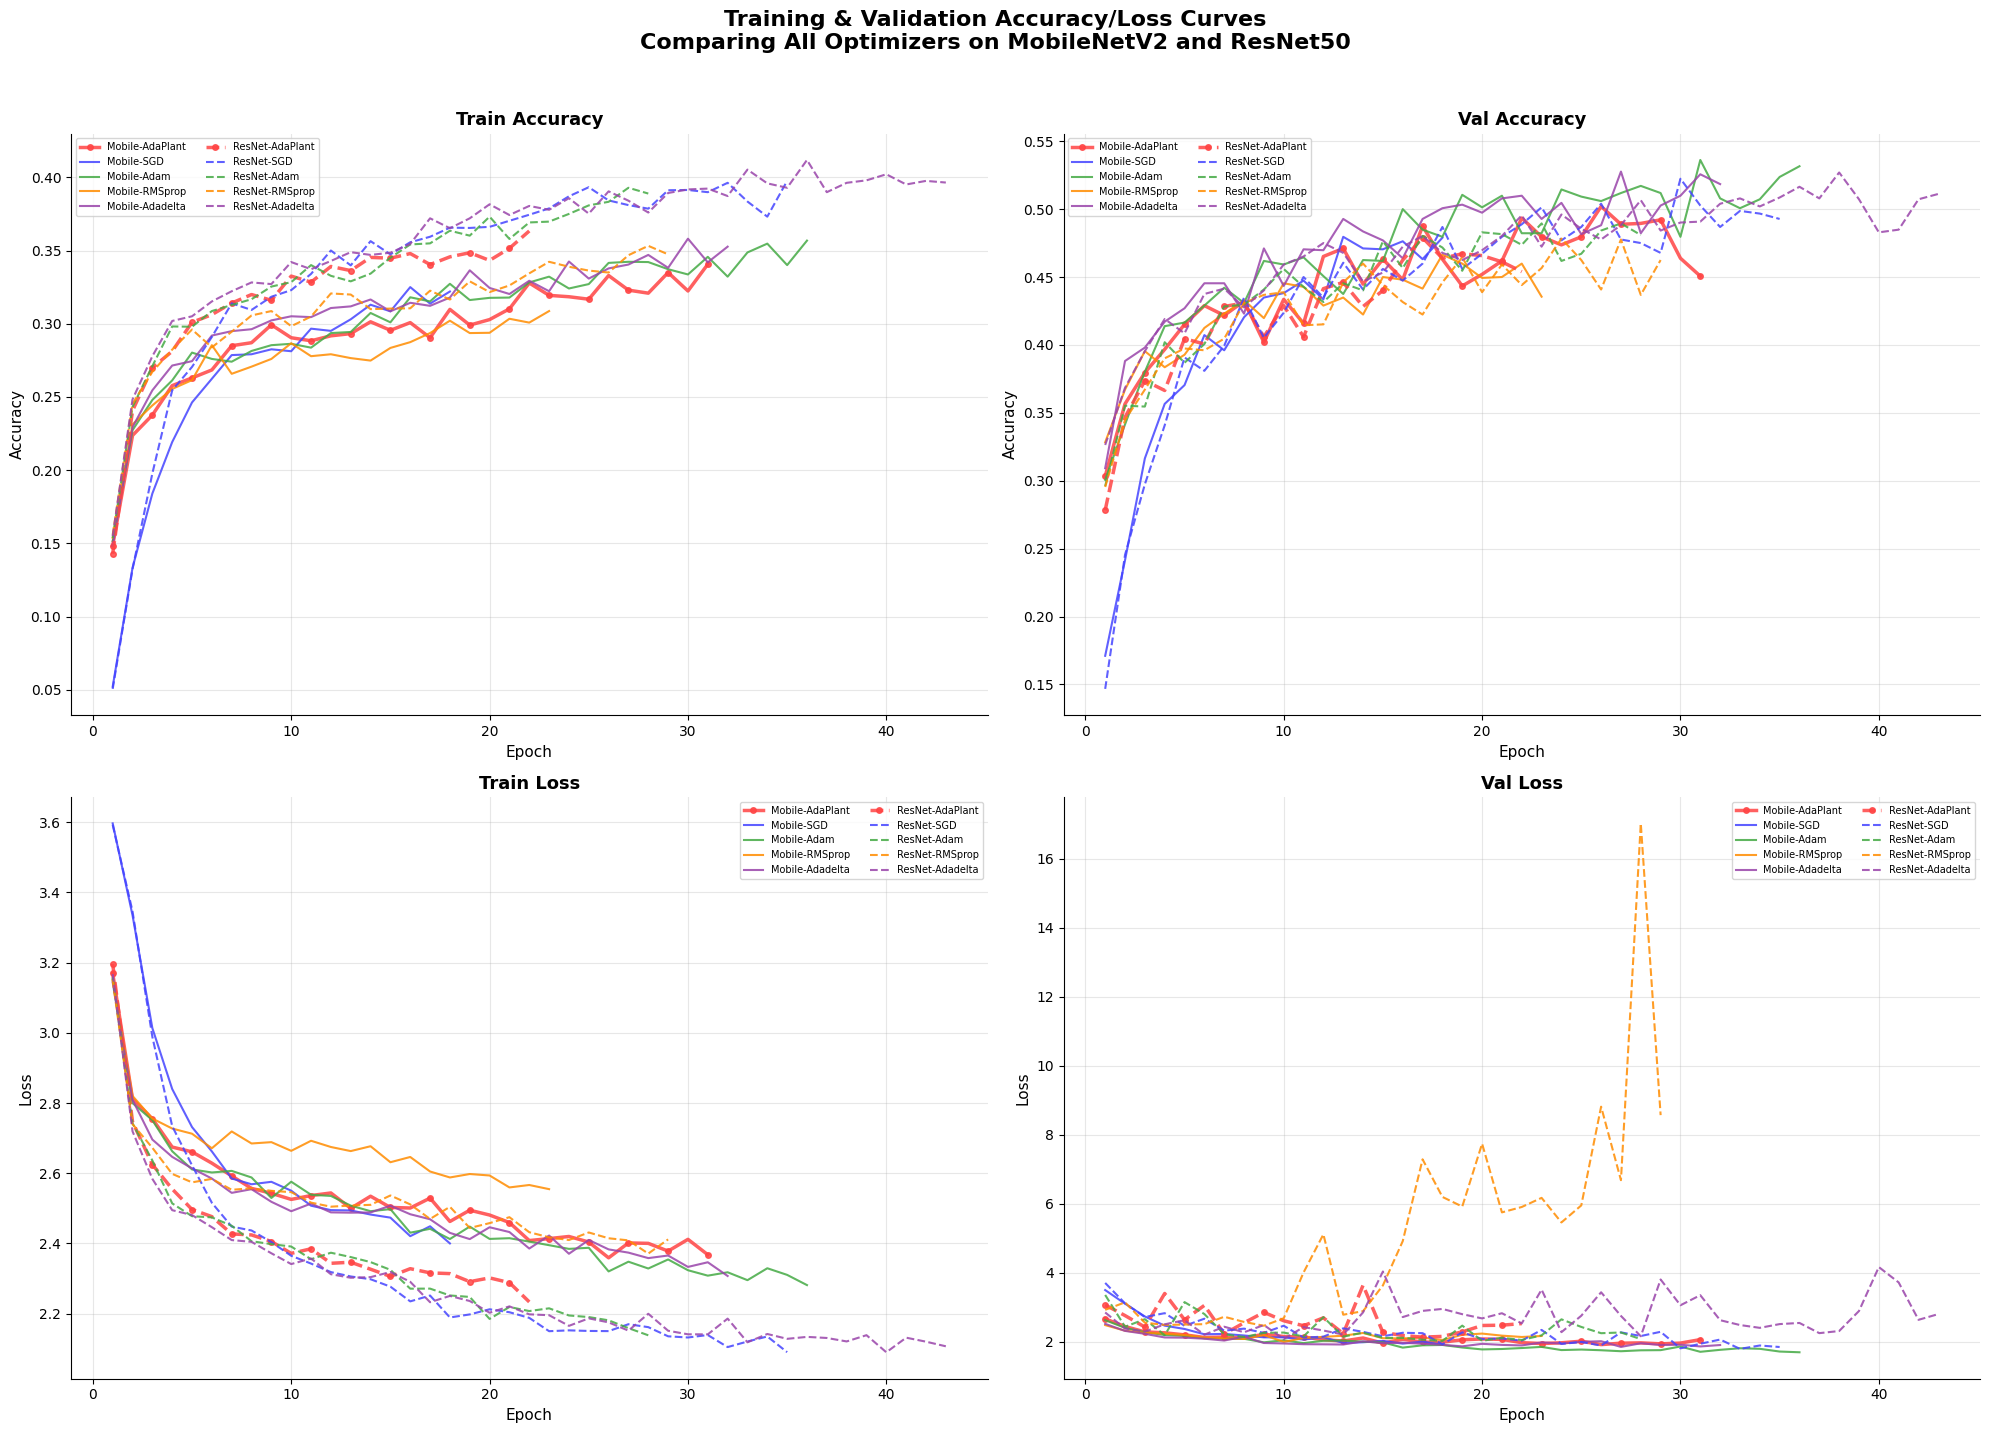

Saved: 1_training_curves.png


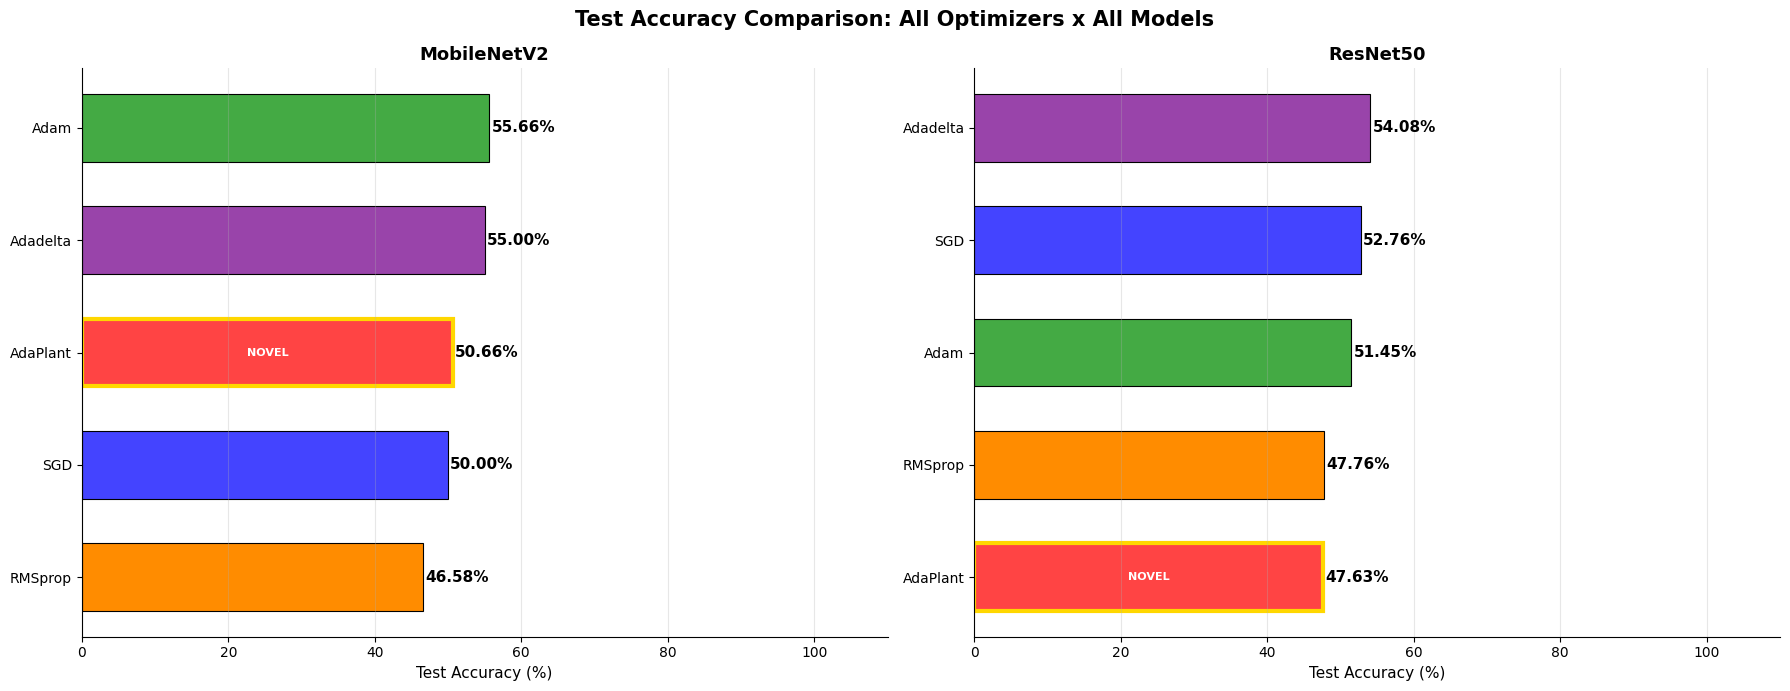

Saved: 2_test_accuracy_bars.png


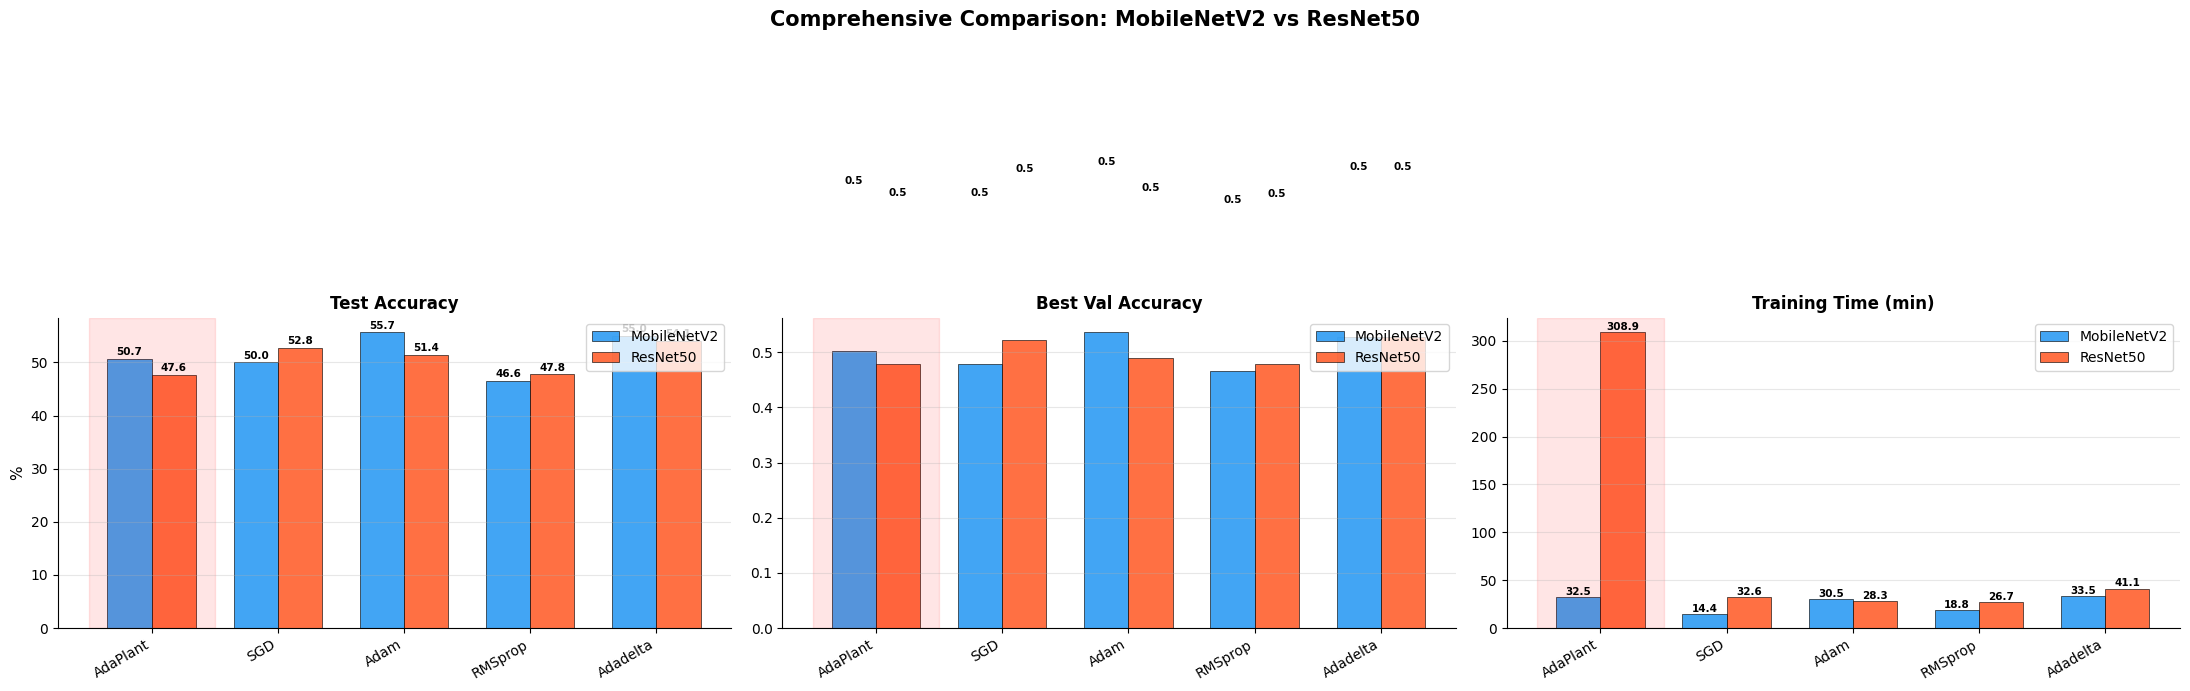

Saved: 3_grouped_comparison.png


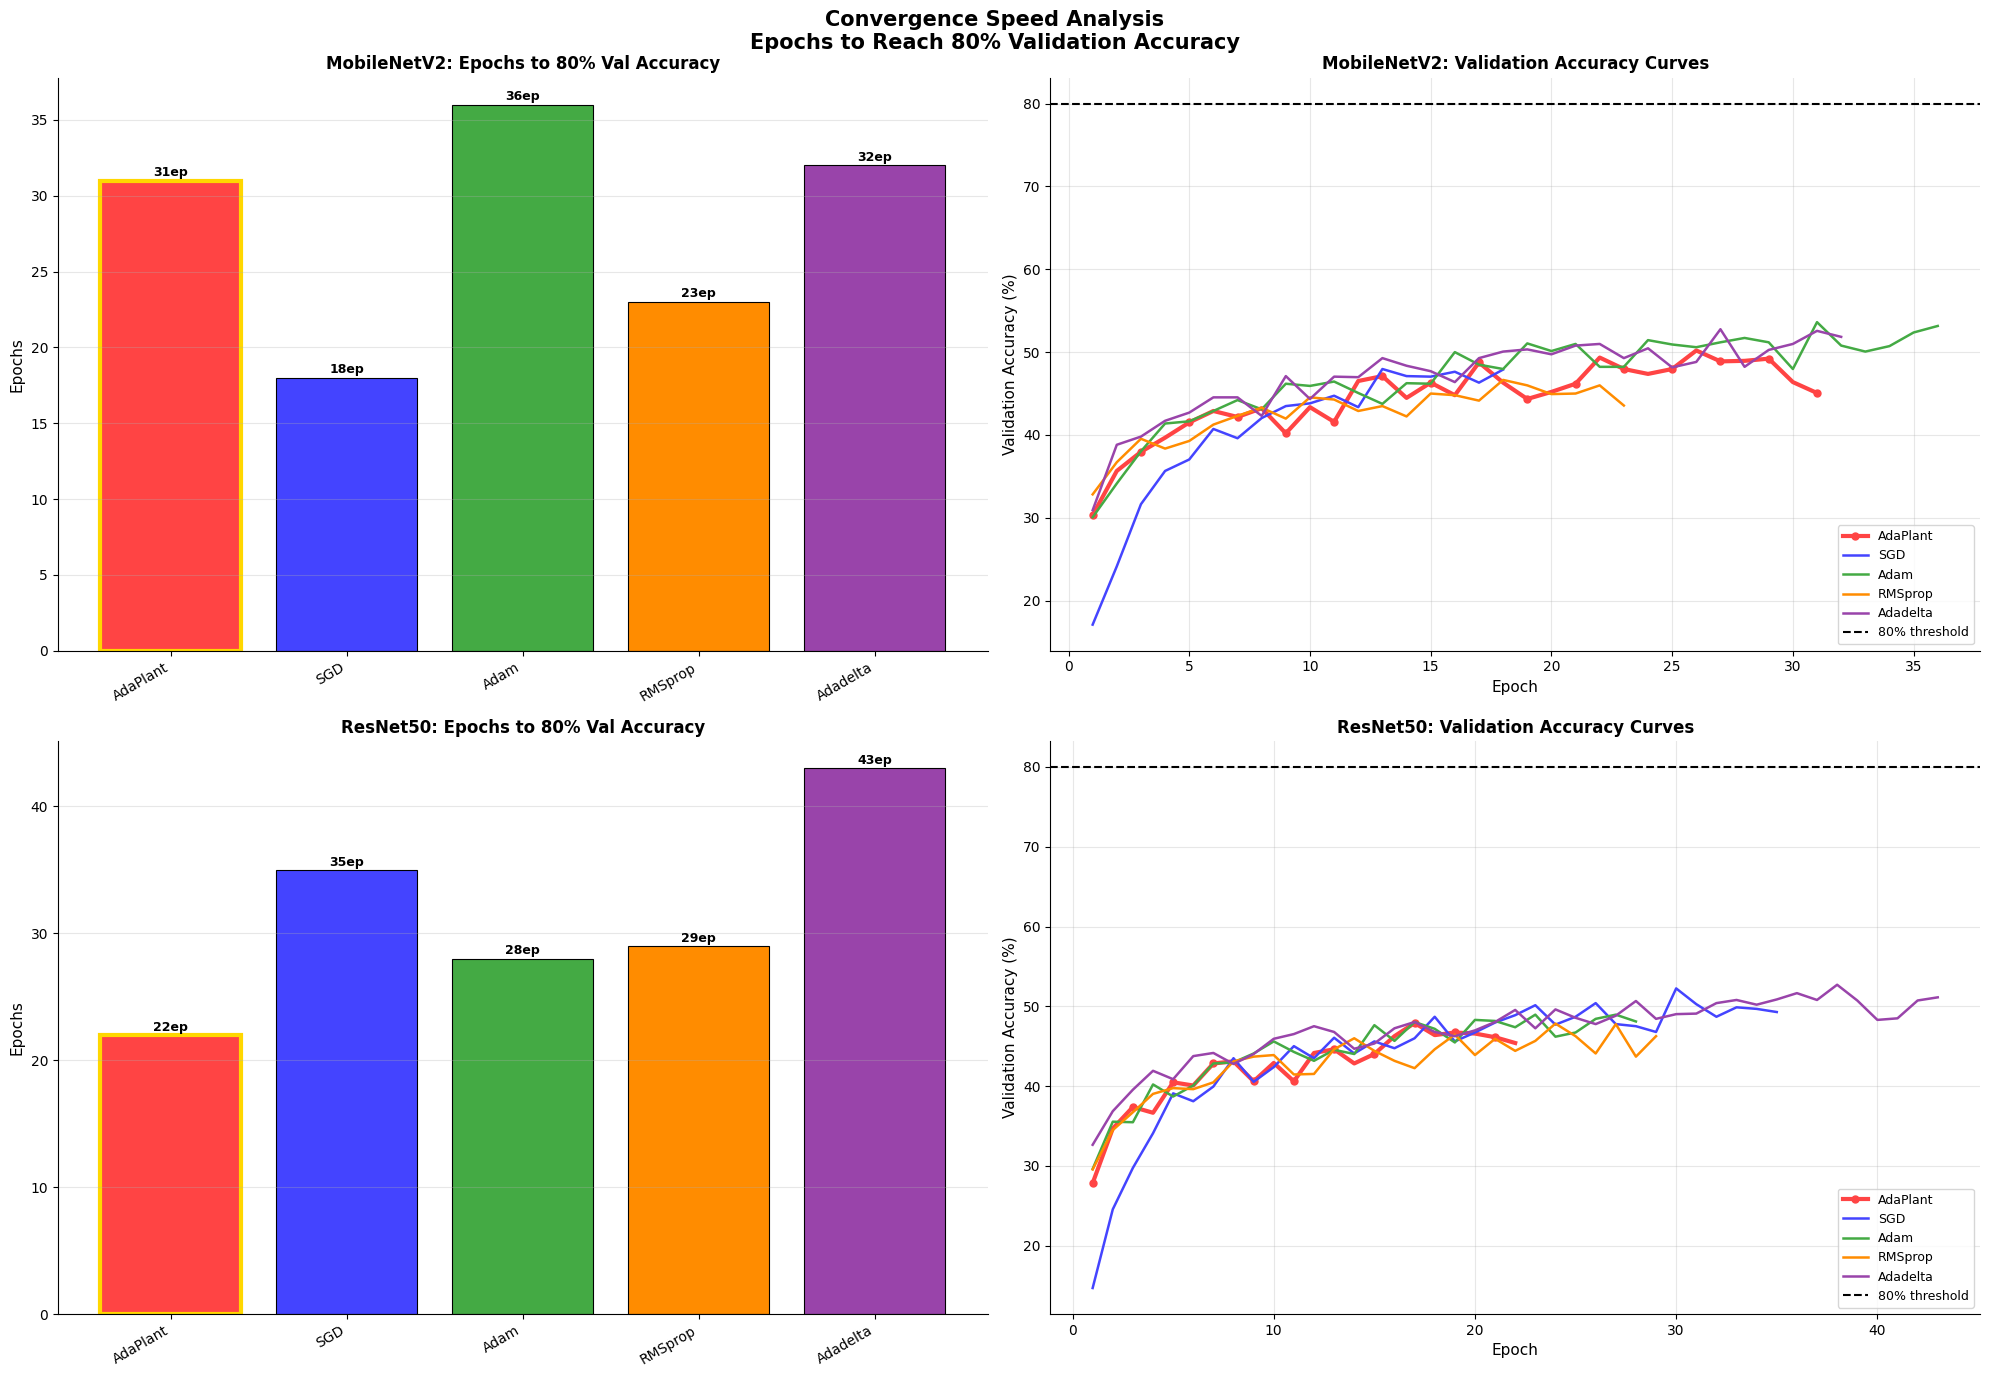

Saved: 4_convergence_analysis.png


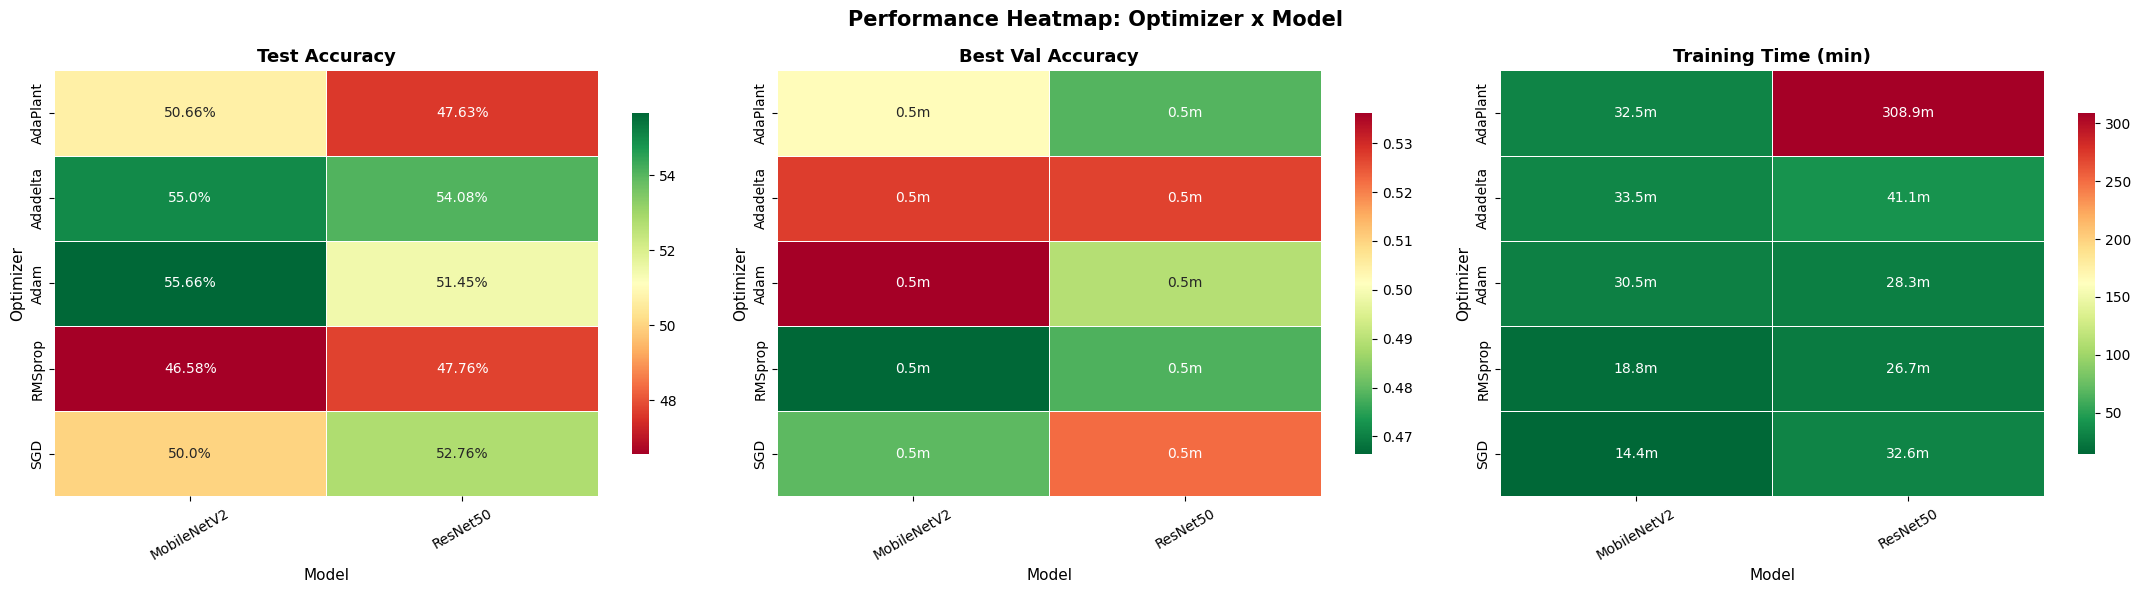

Saved: 5_heatmap_summary.png


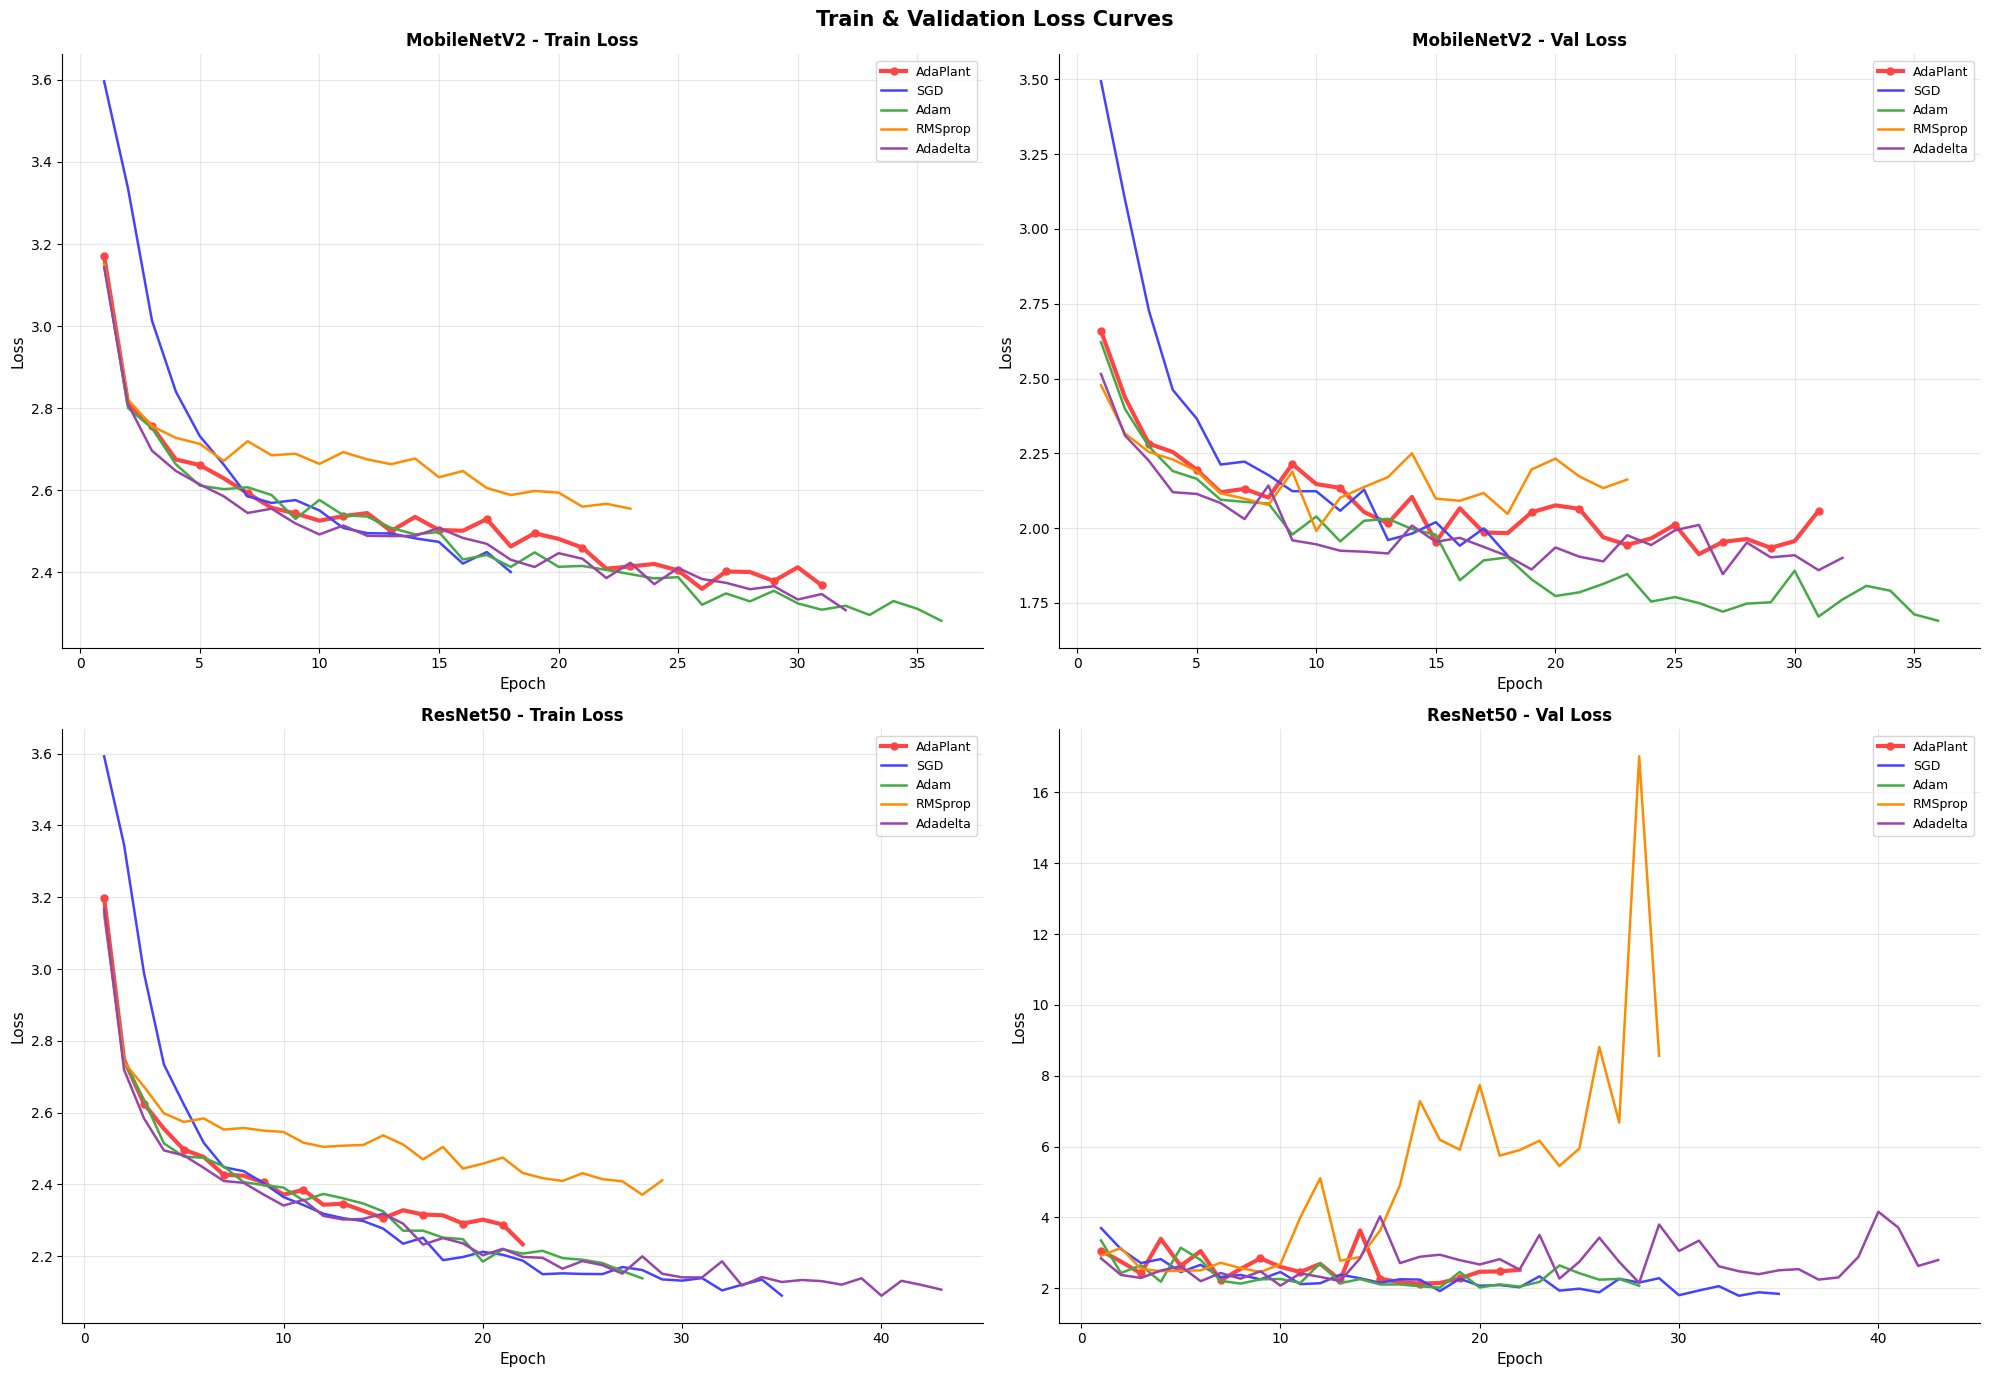

Saved: 6_loss_curves.png


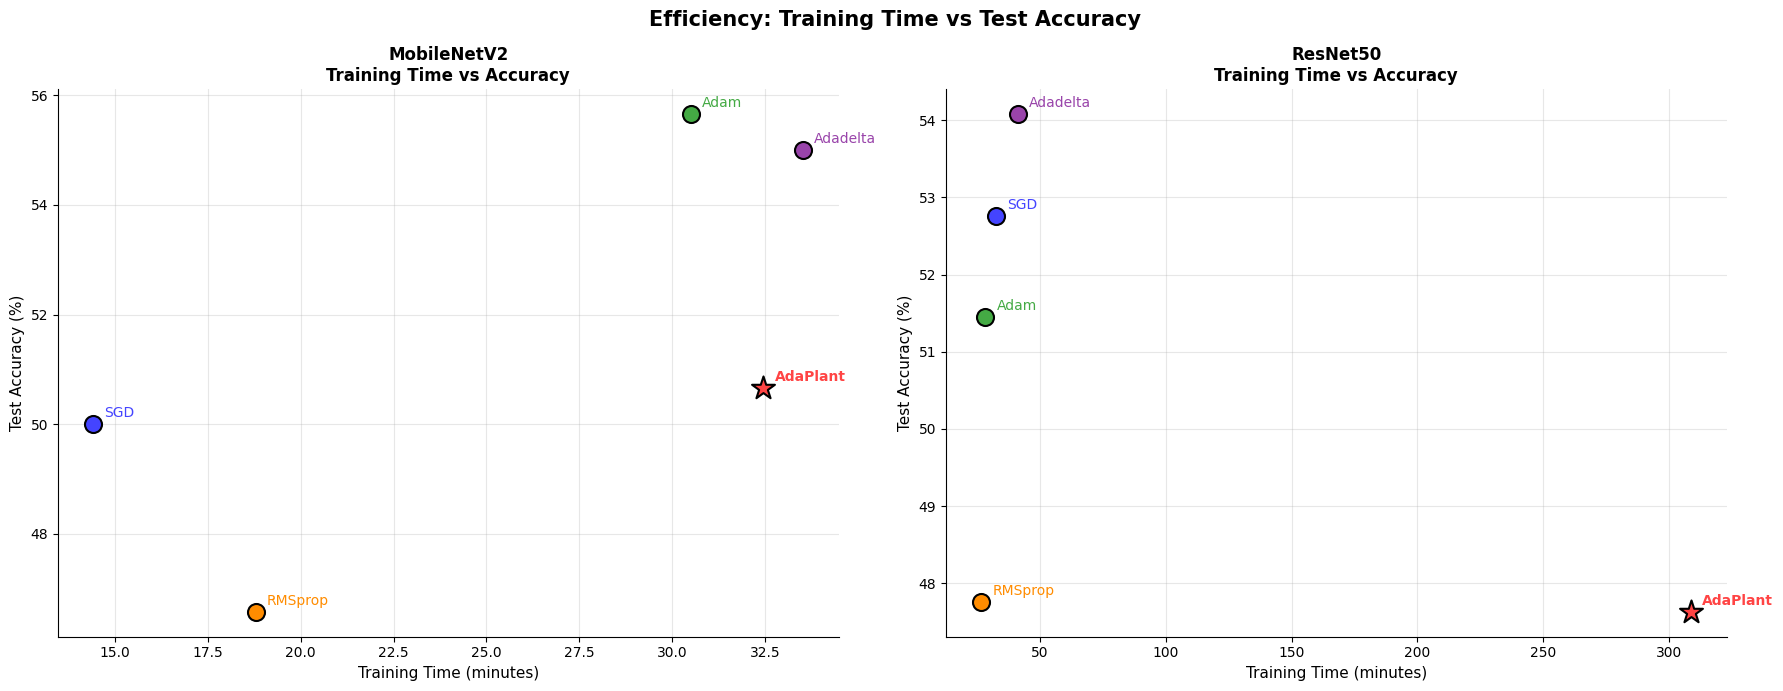

Saved: 7_efficiency_scatter.png


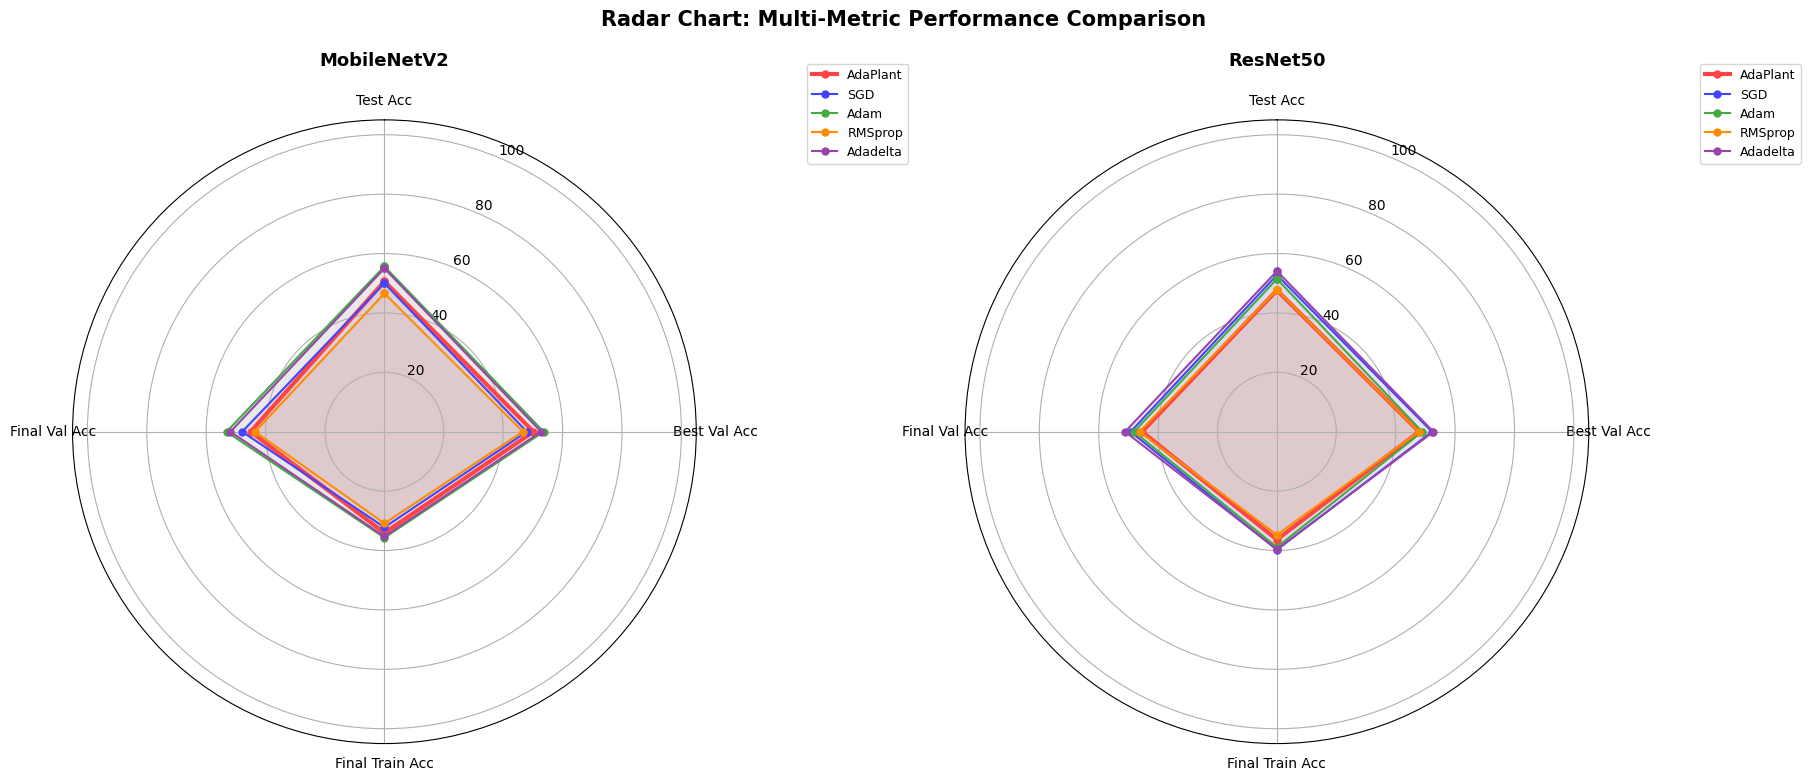

Saved: 8_radar_chart.png


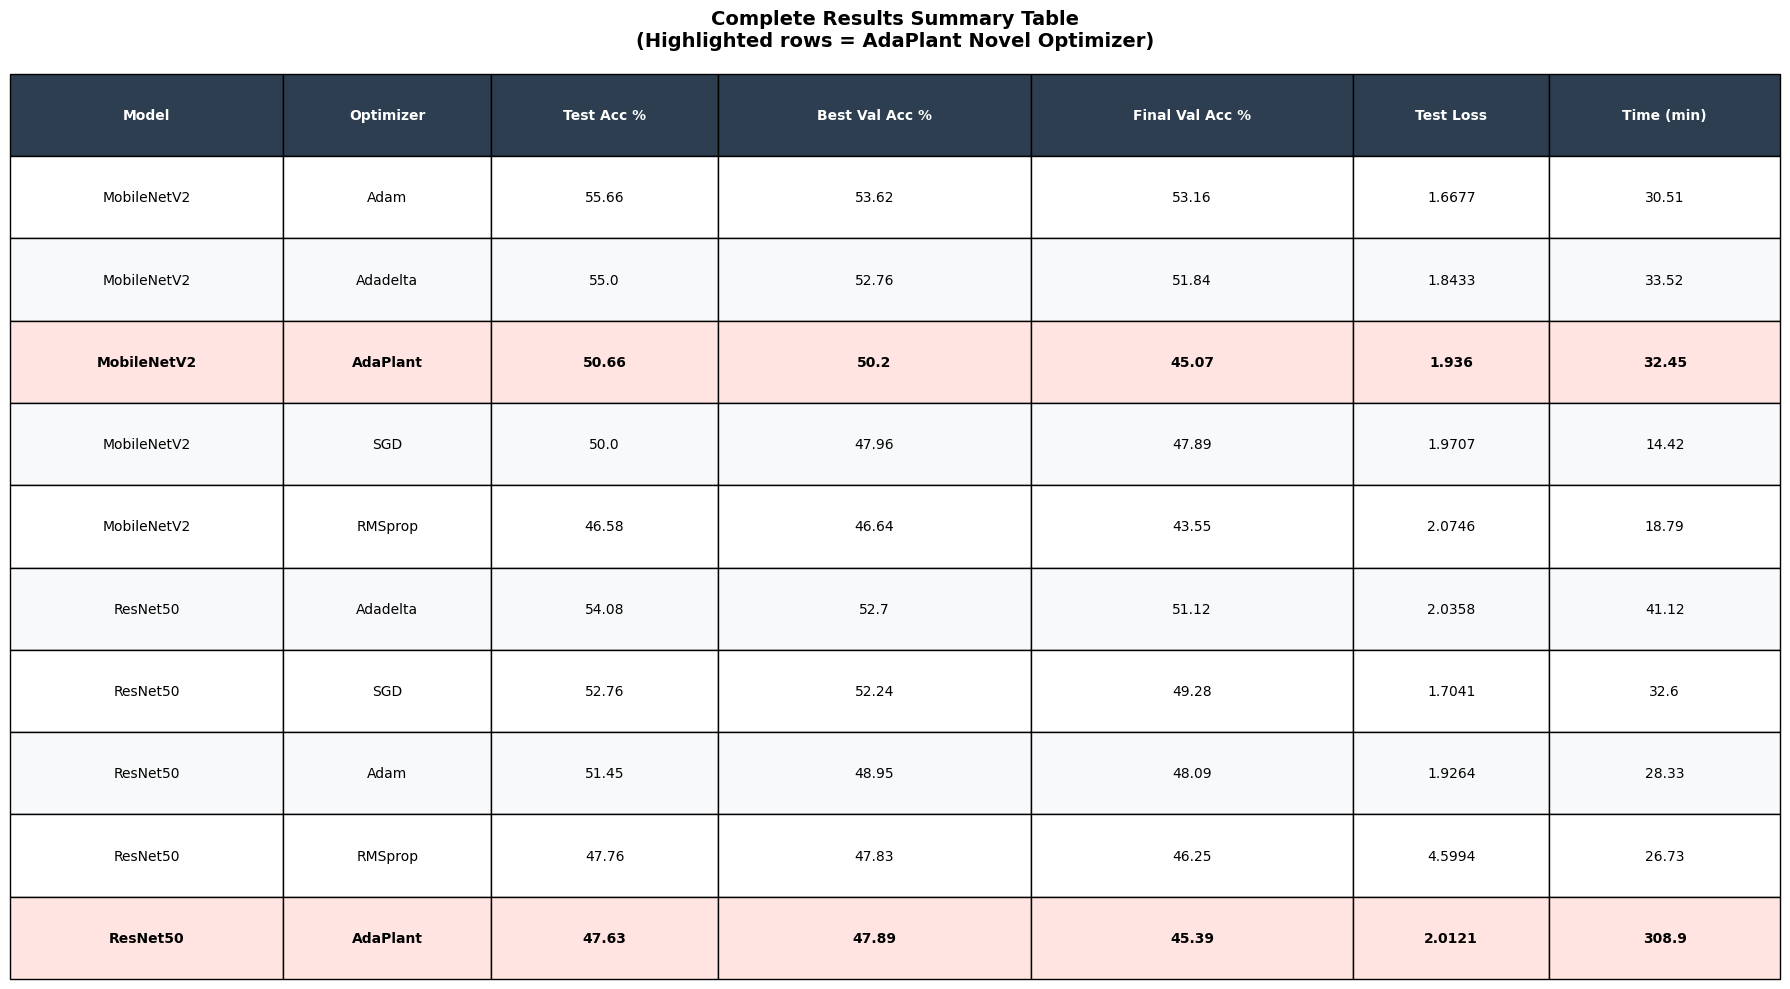

Saved: 9_summary_table.png


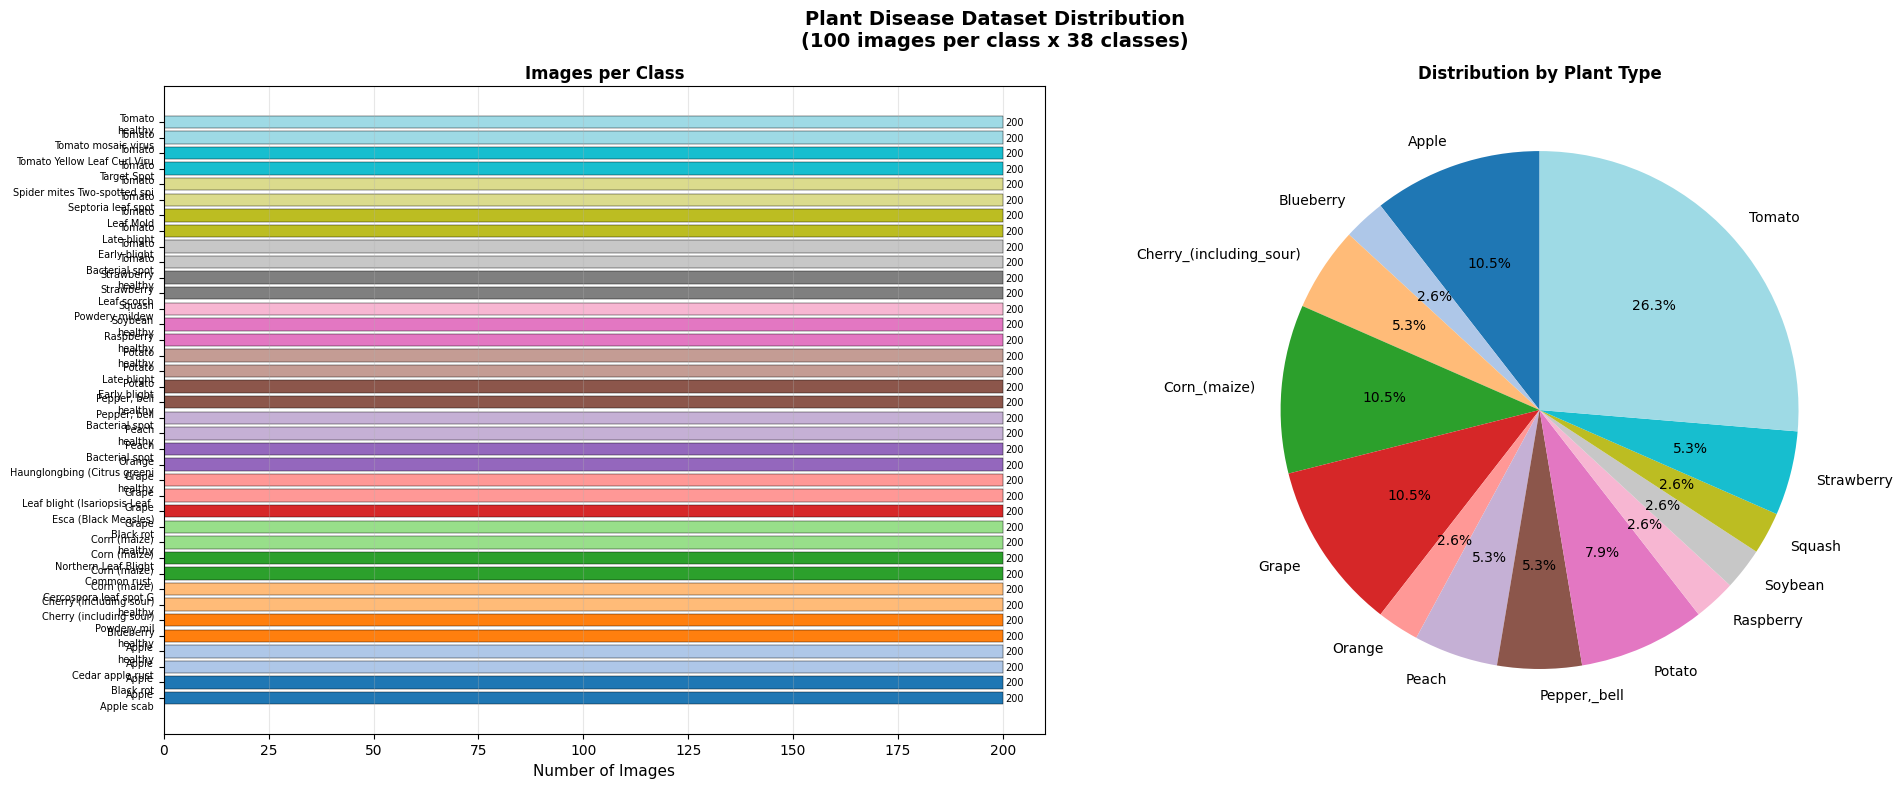

Saved: 10_dataset_distribution.png

  All 10 plots generated and saved!


In [ ]:
# ============================================================
# COMPREHENSIVE VISUALIZATION
# (Unchanged from TF version - uses matplotlib/seaborn)
# ============================================================

class ResultVisualizer:
    """Complete visualization suite for experiment results"""

    def __init__(self, tracker, class_names):
        self.tracker = tracker
        self.class_names = class_names
        self.optimizers = ['AdaPlant', 'SGD', 'Adam', 'RMSprop', 'Adadelta']
        self.models = ['MobileNetV2', 'ResNet50']

        # Color palette
        self.colors = {
            'AdaPlant':  '#FF4444',  # Red (Novel)
            'SGD':       '#4444FF',  # Blue
            'Adam':      '#44AA44',  # Green
            'RMSprop':   '#FF8C00',  # Orange
            'Adadelta':  '#9944AA',  # Purple
        }

        self.line_styles = {
            'MobileNetV2': '-',
            'ResNet50': '--'
        }

    # Plot 1: Training Accuracy Curves
    def plot_training_curves(self):
        fig, axes = plt.subplots(2, 2, figsize=(20, 14))
        fig.suptitle(
            'Training & Validation Accuracy/Loss Curves\n'
            'Comparing All Optimizers on MobileNetV2 and ResNet50',
            fontsize=16, fontweight='bold', y=1.02
        )

        metrics = ['accuracy', 'val_accuracy', 'loss', 'val_loss']
        titles = ['Train Accuracy', 'Val Accuracy', 'Train Loss', 'Val Loss']
        ylabels = ['Accuracy', 'Accuracy', 'Loss', 'Loss']

        for ax, metric, title, ylabel in zip(
            axes.flat, metrics, titles, ylabels
        ):
            for model_name in self.models:
                for opt_name in self.optimizers:
                    key = f"{model_name}_{opt_name}"
                    if key not in self.tracker.histories:
                        continue

                    history = self.tracker.histories[key]
                    if metric not in history:
                        continue

                    values = history[metric]
                    epochs = range(1, len(values) + 1)

                    label = f"{model_name[:6]}-{opt_name}"
                    style = self.line_styles[model_name]
                    color = self.colors[opt_name]
                    lw = 2.5 if opt_name == 'AdaPlant' else 1.5

                    ax.plot(
                        epochs, values,
                        linestyle=style,
                        color=color,
                        linewidth=lw,
                        label=label,
                        alpha=0.85,
                        marker='o' if opt_name == 'AdaPlant' else None,
                        markevery=2,
                        markersize=4
                    )

            ax.set_title(title, fontsize=13, fontweight='bold')
            ax.set_xlabel('Epoch', fontsize=11)
            ax.set_ylabel(ylabel, fontsize=11)
            ax.legend(fontsize=7, ncol=2, loc='best')
            ax.grid(True, alpha=0.3)
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)

        plt.tight_layout()
        plt.savefig('1_training_curves.png', dpi=150, bbox_inches='tight')
        plt.show()
        print("Saved: 1_training_curves.png")

    # Plot 2: Test Accuracy Bar Chart
    def plot_test_accuracy_bars(self):
        df = self.tracker.get_summary_df()

        fig, axes = plt.subplots(1, 2, figsize=(18, 7))
        fig.suptitle(
            'Test Accuracy Comparison: All Optimizers x All Models',
            fontsize=15, fontweight='bold'
        )

        for ax, model_name in zip(axes, self.models):
            model_df = df[df['Model'] == model_name].sort_values(
                'Test_Accuracy', ascending=True
            )

            colors = [self.colors[opt] for opt in model_df['Optimizer']]
            bars = ax.barh(
                model_df['Optimizer'],
                model_df['Test_Accuracy'] * 100,
                color=colors,
                edgecolor='black',
                linewidth=0.8,
                height=0.6
            )

            for bar, val in zip(bars, model_df['Test_Accuracy']):
                ax.text(
                    bar.get_width() + 0.3,
                    bar.get_y() + bar.get_height() / 2,
                    f'{val*100:.2f}%',
                    va='center', ha='left',
                    fontsize=11, fontweight='bold'
                )

            for i, (bar, opt) in enumerate(zip(bars, model_df['Optimizer'])):
                if opt == 'AdaPlant':
                    bar.set_edgecolor('gold')
                    bar.set_linewidth(3)
                    ax.text(
                        bar.get_width() / 2,
                        bar.get_y() + bar.get_height() / 2,
                        'NOVEL',
                        va='center', ha='center',
                        fontsize=8, fontweight='bold', color='white'
                    )

            ax.set_title(f'{model_name}', fontsize=13, fontweight='bold')
            ax.set_xlabel('Test Accuracy (%)', fontsize=11)
            ax.set_xlim(0, 110)
            ax.grid(True, axis='x', alpha=0.3)
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)

        plt.tight_layout()
        plt.savefig('2_test_accuracy_bars.png', dpi=150, bbox_inches='tight')
        plt.show()
        print("Saved: 2_test_accuracy_bars.png")

    # Plot 3: Grouped Bar Chart
    def plot_grouped_comparison(self):
        df = self.tracker.get_summary_df()

        fig, axes = plt.subplots(1, 3, figsize=(22, 7))
        fig.suptitle(
            'Comprehensive Comparison: MobileNetV2 vs ResNet50',
            fontsize=15, fontweight='bold'
        )

        metrics = ['Test_Accuracy', 'Best_Val_Acc', 'Training_Time_min']
        metric_labels = ['Test Accuracy', 'Best Val Accuracy', 'Training Time (min)']

        x = np.arange(len(self.optimizers))
        width = 0.35

        for ax, metric, label in zip(axes, metrics, metric_labels):
            for i, model_name in enumerate(self.models):
                model_df = df[df['Model'] == model_name]

                values = []
                for opt in self.optimizers:
                    row = model_df[model_df['Optimizer'] == opt]
                    if len(row) > 0:
                        val = row[metric].values[0]
                        if 'Accuracy' in metric:
                            val *= 100
                        values.append(val)
                    else:
                        values.append(0)

                offset = width * (i - 0.5)
                bars = ax.bar(
                    x + offset, values,
                    width, label=model_name,
                    alpha=0.85,
                    color=['#2196F3', '#FF5722'][i],
                    edgecolor='black',
                    linewidth=0.5
                )

                for bar, val in zip(bars, values):
                    ax.text(
                        bar.get_x() + bar.get_width() / 2,
                        bar.get_height() + 0.3,
                        f'{val:.1f}',
                        ha='center', va='bottom',
                        fontsize=7.5, fontweight='bold'
                    )

            ax.set_title(label, fontsize=12, fontweight='bold')
            ax.set_xticks(x)
            ax.set_xticklabels(self.optimizers, rotation=30, ha='right')
            ax.legend(fontsize=10)
            ax.grid(True, axis='y', alpha=0.3)
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)

            if 'Accuracy' in metric:
                ax.set_ylabel('%', fontsize=11)

        for ax in axes:
            adaplant_idx = self.optimizers.index('AdaPlant')
            ax.axvspan(
                adaplant_idx - 0.5, adaplant_idx + 0.5,
                alpha=0.1, color='red', label='Novel'
            )

        plt.tight_layout()
        plt.savefig('3_grouped_comparison.png', dpi=150, bbox_inches='tight')
        plt.show()
        print("Saved: 3_grouped_comparison.png")

    # Plot 4: Convergence Speed Analysis
    def plot_convergence_analysis(self):
        fig, axes = plt.subplots(2, 2, figsize=(20, 14))
        fig.suptitle(
            'Convergence Speed Analysis\n'
            'Epochs to Reach 80% Validation Accuracy',
            fontsize=15, fontweight='bold'
        )

        threshold = 0.80

        for ax_row, model_name in enumerate(self.models):
            ax_bar = axes[ax_row, 0]
            ax_line = axes[ax_row, 1]

            convergence_epochs = {}

            for opt_name in self.optimizers:
                key = f"{model_name}_{opt_name}"
                if key not in self.tracker.histories:
                    continue

                val_acc = self.tracker.histories[key]['val_accuracy']

                epochs_to_threshold = len(val_acc)
                for ep, acc in enumerate(val_acc):
                    if acc >= threshold:
                        epochs_to_threshold = ep + 1
                        break

                convergence_epochs[opt_name] = epochs_to_threshold

                epochs = range(1, len(val_acc) + 1)
                lw = 3 if opt_name == 'AdaPlant' else 1.8
                ax_line.plot(
                    epochs, [v*100 for v in val_acc],
                    color=self.colors[opt_name],
                    linewidth=lw,
                    label=opt_name,
                    marker='o' if opt_name == 'AdaPlant' else None,
                    markevery=2, markersize=5
                )

            opts = list(convergence_epochs.keys())
            epochs_vals = list(convergence_epochs.values())
            bar_colors = [self.colors[o] for o in opts]

            bars = ax_bar.bar(
                opts, epochs_vals,
                color=bar_colors,
                edgecolor='black', linewidth=0.8
            )

            for bar, val, opt in zip(bars, epochs_vals, opts):
                lbl = f'{val}ep' if val < CONFIG['epochs'] else 'Not reached'
                ax_bar.text(
                    bar.get_x() + bar.get_width() / 2,
                    bar.get_height() + 0.1,
                    lbl,
                    ha='center', va='bottom',
                    fontsize=9, fontweight='bold'
                )
                if opt == 'AdaPlant':
                    bar.set_edgecolor('gold')
                    bar.set_linewidth(3)

            ax_bar.set_title(
                f'{model_name}: Epochs to {threshold*100:.0f}% Val Accuracy',
                fontsize=12, fontweight='bold'
            )
            ax_bar.set_ylabel('Epochs', fontsize=11)
            ax_bar.set_xticklabels(opts, rotation=30, ha='right')
            ax_bar.grid(True, axis='y', alpha=0.3)
            ax_bar.spines['top'].set_visible(False)
            ax_bar.spines['right'].set_visible(False)

            ax_line.axhline(
                y=threshold*100, color='black',
                linestyle='--', linewidth=1.5,
                label=f'{threshold*100:.0f}% threshold'
            )
            ax_line.set_title(
                f'{model_name}: Validation Accuracy Curves',
                fontsize=12, fontweight='bold'
            )
            ax_line.set_xlabel('Epoch', fontsize=11)
            ax_line.set_ylabel('Validation Accuracy (%)', fontsize=11)
            ax_line.legend(fontsize=9, loc='lower right')
            ax_line.grid(True, alpha=0.3)
            ax_line.spines['top'].set_visible(False)
            ax_line.spines['right'].set_visible(False)

        plt.tight_layout()
        plt.savefig('4_convergence_analysis.png', dpi=150, bbox_inches='tight')
        plt.show()
        print("Saved: 4_convergence_analysis.png")

    # Plot 5: Heatmap Summary
    def plot_heatmap_summary(self):
        df = self.tracker.get_summary_df()

        fig, axes = plt.subplots(1, 3, figsize=(22, 6))
        fig.suptitle(
            'Performance Heatmap: Optimizer x Model',
            fontsize=15, fontweight='bold'
        )

        metrics = ['Test_Accuracy', 'Best_Val_Acc', 'Training_Time_min']
        titles = ['Test Accuracy', 'Best Val Accuracy', 'Training Time (min)']

        for ax, metric, title in zip(axes, metrics, titles):
            pivot_data = df.pivot(
                index='Optimizer',
                columns='Model',
                values=metric
            )

            if 'Accuracy' in metric:
                pivot_data = pivot_data * 100
                annot = pivot_data.round(2).astype(str) + '%'
            else:
                annot = pivot_data.round(1).astype(str) + 'm'

            sns.heatmap(
                pivot_data,
                ax=ax,
                annot=annot,
                fmt='',
                cmap='RdYlGn' if 'Accuracy' in metric else 'RdYlGn_r',
                linewidths=0.5,
                linecolor='white',
                square=False,
                cbar_kws={'shrink': 0.8}
            )

            ax.set_title(title, fontsize=13, fontweight='bold')
            ax.set_xlabel('Model', fontsize=11)
            ax.set_ylabel('Optimizer', fontsize=11)
            ax.tick_params(axis='x', rotation=30)

        plt.tight_layout()
        plt.savefig('5_heatmap_summary.png', dpi=150, bbox_inches='tight')
        plt.show()
        print("Saved: 5_heatmap_summary.png")

    # Plot 6: Loss Curves
    def plot_loss_curves(self):
        fig, axes = plt.subplots(2, 2, figsize=(20, 14))
        fig.suptitle(
            'Train & Validation Loss Curves',
            fontsize=15, fontweight='bold'
        )

        for ax_row, model_name in enumerate(self.models):
            for ax_col, (split, metric) in enumerate(
                [('Train', 'loss'), ('Val', 'val_loss')]
            ):
                ax = axes[ax_row, ax_col]

                for opt_name in self.optimizers:
                    key = f"{model_name}_{opt_name}"
                    if key not in self.tracker.histories:
                        continue

                    values = self.tracker.histories[key][metric]
                    epochs = range(1, len(values) + 1)

                    lw = 3 if opt_name == 'AdaPlant' else 1.8
                    ax.plot(
                        epochs, values,
                        color=self.colors[opt_name],
                        linewidth=lw,
                        label=opt_name,
                        marker='o' if opt_name == 'AdaPlant' else None,
                        markevery=2, markersize=5
                    )

                ax.set_title(
                    f'{model_name} - {split} Loss',
                    fontsize=12, fontweight='bold'
                )
                ax.set_xlabel('Epoch', fontsize=11)
                ax.set_ylabel('Loss', fontsize=11)
                ax.legend(fontsize=9)
                ax.grid(True, alpha=0.3)
                ax.spines['top'].set_visible(False)
                ax.spines['right'].set_visible(False)

        plt.tight_layout()
        plt.savefig('6_loss_curves.png', dpi=150, bbox_inches='tight')
        plt.show()
        print("Saved: 6_loss_curves.png")

    # Plot 7: Training Time vs Accuracy (Scatter)
    def plot_efficiency_scatter(self):
        df = self.tracker.get_summary_df()

        fig, axes = plt.subplots(1, 2, figsize=(18, 7))
        fig.suptitle(
            'Efficiency: Training Time vs Test Accuracy',
            fontsize=15, fontweight='bold'
        )

        for ax, model_name in zip(axes, self.models):
            model_df = df[df['Model'] == model_name]

            for _, row in model_df.iterrows():
                opt = row['Optimizer']
                x = row['Training_Time_min']
                y = row['Test_Accuracy'] * 100

                size = 300 if opt == 'AdaPlant' else 150
                marker = '*' if opt == 'AdaPlant' else 'o'

                ax.scatter(
                    x, y,
                    c=self.colors[opt],
                    s=size,
                    marker=marker,
                    edgecolors='black',
                    linewidth=1.5,
                    zorder=5,
                    label=opt
                )

                ax.annotate(
                    opt,
                    (x, y),
                    textcoords="offset points",
                    xytext=(8, 5),
                    fontsize=10,
                    fontweight='bold' if opt == 'AdaPlant' else 'normal',
                    color=self.colors[opt]
                )

            ax.set_title(
                f'{model_name}\nTraining Time vs Accuracy',
                fontsize=12, fontweight='bold'
            )
            ax.set_xlabel('Training Time (minutes)', fontsize=11)
            ax.set_ylabel('Test Accuracy (%)', fontsize=11)
            ax.grid(True, alpha=0.3)
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)

        plt.tight_layout()
        plt.savefig('7_efficiency_scatter.png', dpi=150, bbox_inches='tight')
        plt.show()
        print("Saved: 7_efficiency_scatter.png")

    # Plot 8: Radar Chart
    def plot_radar_chart(self):
        df = self.tracker.get_summary_df()

        fig, axes = plt.subplots(1, 2, figsize=(18, 8),
                                  subplot_kw=dict(polar=True))
        fig.suptitle(
            'Radar Chart: Multi-Metric Performance Comparison',
            fontsize=15, fontweight='bold'
        )

        metrics_list = ['Test_Accuracy', 'Best_Val_Acc',
                   'Final_Train_Acc', 'Final_Val_Acc']
        metric_labels = ['Test Acc', 'Best Val Acc',
                         'Final Train Acc', 'Final Val Acc']

        N = len(metrics_list)
        angles = np.linspace(0, 2*np.pi, N, endpoint=False).tolist()
        angles += angles[:1]

        for ax, model_name in zip(axes, self.models):
            model_df = df[df['Model'] == model_name]

            ax.set_theta_offset(np.pi / 2)
            ax.set_theta_direction(-1)
            ax.set_xticks(angles[:-1])
            ax.set_xticklabels(metric_labels, fontsize=10)

            for _, row in model_df.iterrows():
                opt = row['Optimizer']
                values = [row[m] * 100 for m in metrics_list]
                values += values[:1]

                lw = 3 if opt == 'AdaPlant' else 1.5
                ax.plot(
                    angles, values,
                    'o-',
                    color=self.colors[opt],
                    linewidth=lw,
                    label=opt,
                    markersize=5
                )
                ax.fill(
                    angles, values,
                    color=self.colors[opt],
                    alpha=0.08
                )

            ax.set_ylim(0, 105)
            ax.set_title(
                f'{model_name}',
                fontsize=13, fontweight='bold', pad=20
            )
            ax.legend(
                loc='upper right',
                bbox_to_anchor=(1.35, 1.1),
                fontsize=9
            )

        plt.tight_layout()
        plt.savefig('8_radar_chart.png', dpi=150, bbox_inches='tight')
        plt.show()
        print("Saved: 8_radar_chart.png")

    # Plot 9: Complete Summary Table
    def plot_summary_table(self):
        df = self.tracker.get_summary_df()

        display_df = pd.DataFrame({
            'Model': df['Model'],
            'Optimizer': df['Optimizer'],
            'Test Acc %': (df['Test_Accuracy'] * 100).round(2),
            'Best Val Acc %': (df['Best_Val_Acc'] * 100).round(2),
            'Final Val Acc %': (df['Final_Val_Acc'] * 100).round(2),
            'Test Loss': df['Test_Loss'].round(4),
            'Time (min)': df['Training_Time_min'].round(2),
        }).sort_values(['Model', 'Test Acc %'], ascending=[True, False])

        fig, ax = plt.subplots(figsize=(18, 10))
        ax.axis('off')

        table = ax.table(
            cellText=display_df.values,
            colLabels=display_df.columns,
            cellLoc='center',
            loc='center',
            bbox=[0, 0, 1, 1]
        )

        table.auto_set_font_size(False)
        table.set_fontsize(10)
        table.auto_set_column_width(col=list(range(len(display_df.columns))))

        for j in range(len(display_df.columns)):
            table[0, j].set_facecolor('#2C3E50')
            table[0, j].set_text_props(color='white', fontweight='bold')

        for i in range(1, len(display_df) + 1):
            opt = display_df.iloc[i-1]['Optimizer']

            if opt == 'AdaPlant':
                row_color = '#FFE4E1'
            elif i % 2 == 0:
                row_color = '#F8F9FA'
            else:
                row_color = 'white'

            for j in range(len(display_df.columns)):
                table[i, j].set_facecolor(row_color)
                if opt == 'AdaPlant':
                    table[i, j].set_text_props(fontweight='bold')

        ax.set_title(
            'Complete Results Summary Table\n'
            '(Highlighted rows = AdaPlant Novel Optimizer)',
            fontsize=14, fontweight='bold', pad=20
        )

        plt.tight_layout()
        plt.savefig('9_summary_table.png', dpi=150, bbox_inches='tight')
        plt.show()
        print("Saved: 9_summary_table.png")

    # Plot 10: Dataset Distribution
    def plot_dataset_distribution(self, class_counts):
        fig, axes = plt.subplots(1, 2, figsize=(20, 8))
        fig.suptitle(
            'Plant Disease Dataset Distribution\n'
            f'(100 images per class x {len(class_counts)} classes)',
            fontsize=14, fontweight='bold'
        )

        ax1 = axes[0]
        classes = list(class_counts.keys())
        counts = list(class_counts.values())

        plant_colors = plt.cm.tab20(np.linspace(0, 1, len(classes)))

        bars = ax1.barh(
            range(len(classes)), counts,
            color=plant_colors, edgecolor='black', linewidth=0.3
        )

        ax1.set_yticks(range(len(classes)))
        ax1.set_yticklabels(
            [c.replace('___', '\n').replace('_', ' ')[:35]
             for c in classes],
            fontsize=7
        )
        ax1.set_xlabel('Number of Images', fontsize=11)
        ax1.set_title('Images per Class', fontsize=12, fontweight='bold')
        ax1.grid(True, axis='x', alpha=0.3)

        for bar, count in zip(bars, counts):
            ax1.text(
                bar.get_width() + 0.5,
                bar.get_y() + bar.get_height() / 2,
                str(count),
                va='center', fontsize=7
            )

        ax2 = axes[1]
        plant_groups = defaultdict(int)
        for cls, count in class_counts.items():
            plant = cls.split('___')[0]
            plant_groups[plant] += count

        ax2.pie(
            plant_groups.values(),
            labels=plant_groups.keys(),
            autopct='%1.1f%%',
            startangle=90,
            colors=plt.cm.tab20(np.linspace(0, 1, len(plant_groups)))
        )
        ax2.set_title('Distribution by Plant Type', fontsize=12, fontweight='bold')

        plt.tight_layout()
        plt.savefig('10_dataset_distribution.png', dpi=150, bbox_inches='tight')
        plt.show()
        print("Saved: 10_dataset_distribution.png")

    def generate_all_plots(self, class_counts):
        """Generate all visualization plots"""
        print("\n" + "=" * 65)
        print("  GENERATING ALL VISUALIZATIONS")
        print("=" * 65)

        self.plot_training_curves()
        self.plot_test_accuracy_bars()
        self.plot_grouped_comparison()
        self.plot_convergence_analysis()
        self.plot_heatmap_summary()
        self.plot_loss_curves()
        self.plot_efficiency_scatter()
        self.plot_radar_chart()
        self.plot_summary_table()
        self.plot_dataset_distribution(class_counts)

        print("\n  All 10 plots generated and saved!")


# ============================================================
# GENERATE ALL VISUALIZATIONS
# ============================================================
visualizer = ResultVisualizer(
    tracker=tracker,
    class_names=data_loader.class_names
)

visualizer.generate_all_plots(class_counts)

In [14]:
# ============================================================
# FINAL RESULTS SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("  FINAL RESULTS SUMMARY")
print("=" * 70)

df = tracker.get_summary_df()

print("\n  Complete Results Table:")
print("-" * 70)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 120)
pd.set_option('display.float_format', '{:.4f}'.format)
print(df.to_string(index=False))

print("\n\n  Best Results per Model:")
print("-" * 70)

for model_name in ['MobileNetV2', 'ResNet50']:
    model_df = df[df['Model'] == model_name].sort_values('Test_Accuracy', ascending=False)
    best = model_df.iloc[0]

    print(f"\n  {model_name}:")
    print(f"  |  Best Optimizer:  {best['Optimizer']}")
    print(f"  |  Test Accuracy:   {best['Test_Accuracy']*100:.2f}%")
    print(f"  |  Best Val Acc:    {best['Best_Val_Acc']*100:.2f}%")
    print(f"  |  Training Time:   {best['Training_Time_min']:.2f} min")

print("\n\n  AdaPlant vs Baselines:")
print("-" * 70)

for model_name in ['MobileNetV2', 'ResNet50']:
    model_df = df[df['Model'] == model_name]
    adaplant_acc = model_df[model_df['Optimizer'] == 'AdaPlant']['Test_Accuracy'].values[0]

    print(f"\n  {model_name}:")
    print(f"  {'Optimizer':<15} {'Test Acc':>10}  vs AdaPlant")
    print(f"  {'-'*45}")

    for _, row in model_df.iterrows():
        opt = row['Optimizer']
        acc = float(row['Test_Accuracy'])
        diff = (acc - adaplant_acc) * 100
        marker = ' <-- NOVEL' if opt == 'AdaPlant' else ''

        if opt == 'AdaPlant':
            diff_str = '+/-0.00%'
        else:
            diff_str = f'{diff:+.2f}%'

        print(f"  {opt:<15} {acc*100:>9.2f}%  {diff_str:>10}{marker}")


# Save results to JSON
results_dict = df.to_dict(orient='records')
with open('experiment_results.json', 'w') as f:
    json.dump(results_dict, f, indent=2, default=str)

print("\n\n  Results saved to: experiment_results.json")
print("=" * 70)


  FINAL RESULTS SUMMARY

  Complete Results Table:
----------------------------------------------------------------------
      Model Optimizer  Best_Val_Acc  Final_Train_Acc  Final_Val_Acc  Best_Val_Loss  Final_Train_Loss  Final_Val_Loss  Test_Accuracy  Test_Loss  Training_Time_min
MobileNetV2  AdaPlant        0.5020           0.3406         0.4507         1.9130            2.3679          2.0578         0.5066     1.9360            32.4529
MobileNetV2       SGD        0.4796           0.3220         0.4789         1.9087            2.4001          1.9087         0.5000     1.9707            14.4196
MobileNetV2      Adam        0.5362           0.3568         0.5316         1.6905            2.2814          1.6905         0.5566     1.6677            30.5080
MobileNetV2   RMSprop        0.4664           0.3086         0.4355         1.9911            2.5547          2.1624         0.4658     2.0746            18.7916
MobileNetV2  Adadelta        0.5276           0.3526         0.5184

In [15]:
# ============================================================
# GPU MEMORY CLEANUP
# ============================================================
if torch.cuda.is_available():
    torch.cuda.empty_cache()
    print(f"GPU memory freed. Current allocation: {torch.cuda.memory_allocated() / 1e9:.2f} GB")
    print(f"GPU memory cached: {torch.cuda.memory_reserved() / 1e9:.2f} GB")
else:
    print("Running on CPU - no GPU memory to free.")

Running on CPU - no GPU memory to free.
